# SMAI Assignment 3, Part 1: Census Income Prediction with Random Forests (from scratch)

**Student username:** `anagha.prajapati`  (institute e-mail `anagha.prajapati@students.iiit.ac.in`)

This notebook implements **every learning algorithm from scratch with NumPy**: the CART decision tree (split search, growth, stopping rules, prediction), bootstrap sampling, bagging, the Random Forest (per-node random feature selection, majority voting, out-of-bag evaluation), both feature-importance methods, and every evaluation metric. No decision-tree / random-forest / metric implementation from any library is used.

Libraries used:
* `numpy`, `pandas`: arrays and table handling (loading the CSV files, displaying result tables).
* `matplotlib`: plots.
* `joblib`: **only** to run independent tree fits on several CPU cores at the same time in the hyperparameter sweeps of Section 1.6 (an ensemble's trees are independent of each other). Each tree is still built by our own `DecisionTree` code. Because every tree gets its own fixed random stream, the results are **identical for any number of workers**; only the wall-clock time changes.

**Training times.** Every experiment that *compares* training times (1.2, 1.3.2, 1.4.1, 1.4.3, 1.4.4) fits its trees **sequentially on one core**. Wall-clock time on a laptop is noisy (other programs, and performance versus efficiency cores), so those tables also report a **machine-independent cost**: the number of feature values the split search had to examine ("work", in millions). It is counted inside `DecisionTree` and is exactly reproducible.

**Runtime.** Running the whole notebook takes roughly 45–60 minutes on a 12-core laptop.

**Reproducibility:** the personalised seed is derived from the username with SHA-256 (as required) and is used for **every** random number generator in this notebook (stratified split, bootstrap samples, per-node feature sampling, permutation importance).

**Plots:** every plot has the username in its title, carries the required `plt.text(...)` watermark, and is also saved as `figures/anagha.prajapati_<name>.png`.

**Data:** the notebook expects `adult.data` and `adult.test` (UCI Adult) in `./adult/` (or in the working directory).

| Section | Content |
|---|---|
| 1.1 | Data exploration, missing values, redundancy, stratified split, one-hot encoding |
| 1.2 | Decision tree from scratch: split search, implementation, depth experiment, Gini vs entropy |
| 1.3 | Bootstrap sampling, bagged trees |
| 1.4 | Random Forest from scratch: implementation, feature-subset size m, number of trees, tree vs forest |
| 1.5 | Out-of-bag evaluation |
| 1.6 | Bias–variance study and hyperparameter selection |
| 1.7 | Impurity-based and permutation feature importance |
| 1.8 | Final test-set evaluation and error analysis |

## 0. Setup: seed, imports and plotting helpers

In [1]:
import os
import sys
import time
import math
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from joblib import Parallel, delayed  # used only to fit independent trees on several cores

from IPython.display import display

# ---------------------------------------------------------------- personalised seed
USERNAME = "anagha.prajapati"  # part of the IIITH e-mail before '@'
SEED = int(hashlib.sha256(USERNAME.encode()).hexdigest(), 16) % (2**32)
print(f"username = {USERNAME}")
print(f"SEED     = {SEED}")

from joblib import cpu_count
N_JOBS = cpu_count(only_physical_cores=True)  # worker processes for fitting the trees of an ensemble
print(f"CPU cores used for ensemble fitting: {N_JOBS}")
sys.setrecursionlimit(10_000)  # tree growth is recursive; unrestricted trees are ~50-80 levels deep

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 120)

# ---------------------------------------------------------------- plotting helpers
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7")
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": INK2, "ytick.color": INK2, "lines.linewidth": 2, "lines.markersize": 7,
    "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET]),
})
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_orange", [BLUE, "#f0efec", ORANGE])
SEQUENTIAL = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#9ec5f4", "#2a78d6", "#0d366b"])

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def titled(ax, text):
    """Axis title that always contains the username."""
    ax.set_title(f"{text}\n({USERNAME})")


def finish(fig, name):
    """Add the username watermark to every axis, save as figures/<username>_<name>.png and show.
    (Heat-maps carry the username in their title only, so the watermark does not hide cell values.)"""
    for ax in fig.axes:
        if ax.get_label() == "<colorbar>" or ax.images:
            continue
        ax.text(0.95, 0.95, USERNAME, ha="right", va="top", transform=ax.transAxes,
                fontsize=10, color="gray", alpha=0.7)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"{USERNAME}_{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()


class fmt:
    """Number formatting for result tables: fmt(df).format("{:.4f}", subset=[cols]) or .format({col: spec}).
    Renders as a normal table in the notebook and as plain text everywhere else."""

    def __init__(self, df):
        self.df, self.show_index = df.copy(), True

    def format(self, spec, subset=None):
        specs = spec if isinstance(spec, dict) else {c: spec for c in (subset if subset is not None else self.df.columns)}
        for col, f in specs.items():
            self.df[col] = self.df[col].map(f.format)
        return self

    def hide(self, axis="index"):
        self.show_index = False
        return self

    def _repr_html_(self):
        return self.df.to_html(index=self.show_index)

    def __repr__(self):
        return self.df.to_string(index=self.show_index)

username = anagha.prajapati
SEED     = 2679482985


CPU cores used for ensemble fitting: 12


---
# 1.1 Data Preprocessing

## 1.1.1 Dataset Exploration

`adult.data` (32,561 rows) is the development set (later split into train/validation). `adult.test` (16,281 rows) is the official test set. While loading:
* fields are separated by `", "`, so leading spaces are skipped;
* missing values are encoded as `?` and are converted to `NaN`;
* the first line of `adult.test` (`|1x3 Cross validator`) is skipped;
* the test labels end with a full stop (`<=50K.`); the full stop is removed so both files use the same labels.

In [2]:
COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
           "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
           "hours-per-week", "native-country", "income"]
NUMERICAL = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
CATEGORICAL = ["workclass", "education", "marital-status", "occupation", "relationship",
               "race", "sex", "native-country"]
TARGET = "income"
POSITIVE = ">50K"  # positive class (label 1)

# locate the data directory
DATA_DIR = next(d for d in ["adult", ".", "data/adult", "../adult", "data"]
                if os.path.exists(os.path.join(d, "adult.data")))


def load_adult(path, skiprows=0):
    df = pd.read_csv(path, header=None, names=COLUMNS, skipinitialspace=True,
                     na_values="?", skiprows=skiprows)
    df = df.dropna(how="all")                                   # trailing blank lines
    df[TARGET] = df[TARGET].str.strip().str.rstrip(".")         # '<=50K.' -> '<=50K'
    return df.reset_index(drop=True)


dev_df = load_adult(os.path.join(DATA_DIR, "adult.data"))
test_df = load_adult(os.path.join(DATA_DIR, "adult.test"), skiprows=1)
full_df = pd.concat([dev_df, test_df], ignore_index=True)

shape_table = pd.DataFrame(
    {"rows": [len(dev_df), len(test_df), len(full_df)],
     "columns (incl. target)": [dev_df.shape[1], test_df.shape[1], full_df.shape[1]],
     "input features": [dev_df.shape[1] - 1] * 3},
    index=["adult.data (development)", "adult.test (test)", "combined"])
display(shape_table)
display(dev_df.head())

,rows,columns (incl. target),input features
adult.data (development),32561,15,14
adult.test (test),16281,15,14
combined,48842,15,14


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# data type, number of unique values and number of missing values of every feature
rows = []
for col in COLUMNS[:-1]:
    rows.append({
        "feature": col,
        "type": "numerical" if col in NUMERICAL else "categorical",
        "pandas dtype": str(dev_df[col].dtype),
        "unique values (combined, excl. missing)": full_df[col].nunique(),
        "missing (adult.data)": int(dev_df[col].isna().sum()),
        "missing (adult.test)": int(test_df[col].isna().sum()),
        "missing (combined)": int(full_df[col].isna().sum()),
        "missing % (combined)": round(100 * full_df[col].isna().mean(), 2),
    })
feature_table = pd.DataFrame(rows).set_index("feature")
display(feature_table)

print("Number of unique values of the categorical features (adult.data / adult.test / combined):")
for col in CATEGORICAL:
    print(f"  {col:15s}: {dev_df[col].nunique():3d} / {test_df[col].nunique():3d} / {full_df[col].nunique():3d}")
print(f"\nTotal missing cells: adult.data = {int(dev_df.isna().sum().sum())}, "
      f"adult.test = {int(test_df.isna().sum().sum())}")

,type,pandas dtype,"unique values (combined, excl. missing)",missing (adult.data),missing (adult.test),missing (combined),missing % (combined)
feature,,,,,,,
age,numerical,int64,74,0,0,0,0.00
workclass,categorical,str,8,1836,963,2799,5.73
fnlwgt,numerical,int64,28523,0,0,0,0.00
education,categorical,str,16,0,0,0,0.00
education-num,numerical,int64,16,0,0,0,0.00
marital-status,categorical,str,7,0,0,0,0.00
occupation,categorical,str,14,1843,966,2809,5.75
relationship,categorical,str,6,0,0,0,0.00
race,categorical,str,5,0,0,0,0.00


Number of unique values of the categorical features (adult.data / adult.test / combined):
  workclass      :   8 /   8 /   8
  education      :  16 /  16 /  16
  marital-status :   7 /   7 /   7
  occupation     :  14 /  14 /  14
  relationship   :   6 /   6 /   6
  race           :   5 /   5 /   5
  sex            :   2 /   2 /   2
  native-country :  41 /  40 /  41

Total missing cells: adult.data = 4262, adult.test = 2203


In [4]:
# categories of each categorical feature (sorted by frequency in adult.data)
for col in CATEGORICAL:
    vc = dev_df[col].value_counts()
    print(f"{col} ({len(vc)} categories): " + ", ".join(f"{k} ({v})" for k, v in vc.items()))
    print()

workclass (8 categories): Private (22696), Self-emp-not-inc (2541), Local-gov (2093), State-gov (1298), Self-emp-inc (1116), Federal-gov (960), Without-pay (14), Never-worked (7)

education (16 categories): HS-grad (10501), Some-college (7291), Bachelors (5355), Masters (1723), Assoc-voc (1382), 11th (1175), Assoc-acdm (1067), 10th (933), 7th-8th (646), Prof-school (576), 9th (514), 12th (433), Doctorate (413), 5th-6th (333), 1st-4th (168), Preschool (51)

marital-status (7 categories): Married-civ-spouse (14976), Never-married (10683), Divorced (4443), Separated (1025), Widowed (993), Married-spouse-absent (418), Married-AF-spouse (23)

occupation (14 categories): Prof-specialty (4140), Craft-repair (4099), Exec-managerial (4066), Adm-clerical (3770), Sales (3650), Other-service (3295), Machine-op-inspct (2002), Transport-moving (1597), Handlers-cleaners (1370), Farming-fishing (994), Tech-support (928), Protective-serv (649), Priv-house-serv (149), Armed-Forces (9)

relationship (6 c

,n(<=50K),n(>50K),prop(<=50K),prop(>50K)
set,,,,
adult.data,24720,7841,0.7592,0.2408
adult.test,12435,3846,0.7638,0.2362
combined,37155,11687,0.7607,0.2393


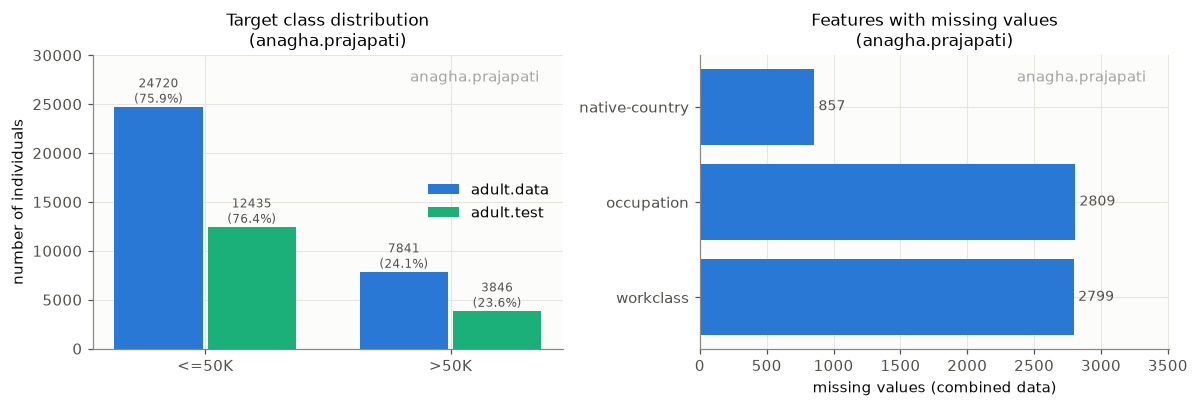

In [5]:
# target class distribution
cls_rows = []
for name, df in [("adult.data", dev_df), ("adult.test", test_df), ("combined", full_df)]:
    vc = df[TARGET].value_counts()
    cls_rows.append({"set": name, "n(<=50K)": vc["<=50K"], "n(>50K)": vc[">50K"],
                     "prop(<=50K)": round(vc["<=50K"] / len(df), 4), "prop(>50K)": round(vc[">50K"] / len(df), 4)})
class_table = pd.DataFrame(cls_rows).set_index("set")
display(class_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
x = np.arange(2)
for k, (name, df) in enumerate([("adult.data", dev_df), ("adult.test", test_df)]):
    counts = df[TARGET].value_counts().reindex(["<=50K", ">50K"]).values
    bars = ax.bar(x + (k - 0.5) * 0.38, counts, width=0.36, label=name, color=[BLUE, AQUA][k])
    for b, c in zip(bars, counts):
        ax.text(b.get_x() + b.get_width() / 2, c, f"{c}\n({c / len(df):.1%})", ha="center", va="bottom", fontsize=8, color=INK2)
ax.set_xticks(x, ["<=50K", ">50K"])
ax.set_ylabel("number of individuals")
ax.set_ylim(0, 30000)
ax.legend(loc="center right")
titled(ax, "Target class distribution")

ax = axes[1]
miss = feature_table["missing (combined)"]
miss = miss[miss > 0]
ax.barh(miss.index, miss.values, color=BLUE)
for i, v in enumerate(miss.values):
    ax.text(v, i, f" {v}", va="center", fontsize=9, color=INK2)
ax.set_xlabel("missing values (combined data)")
ax.set_xlim(0, miss.max() * 1.25)
titled(ax, "Features with missing values")
finish(fig, "1_1_1_class_distribution_missing")

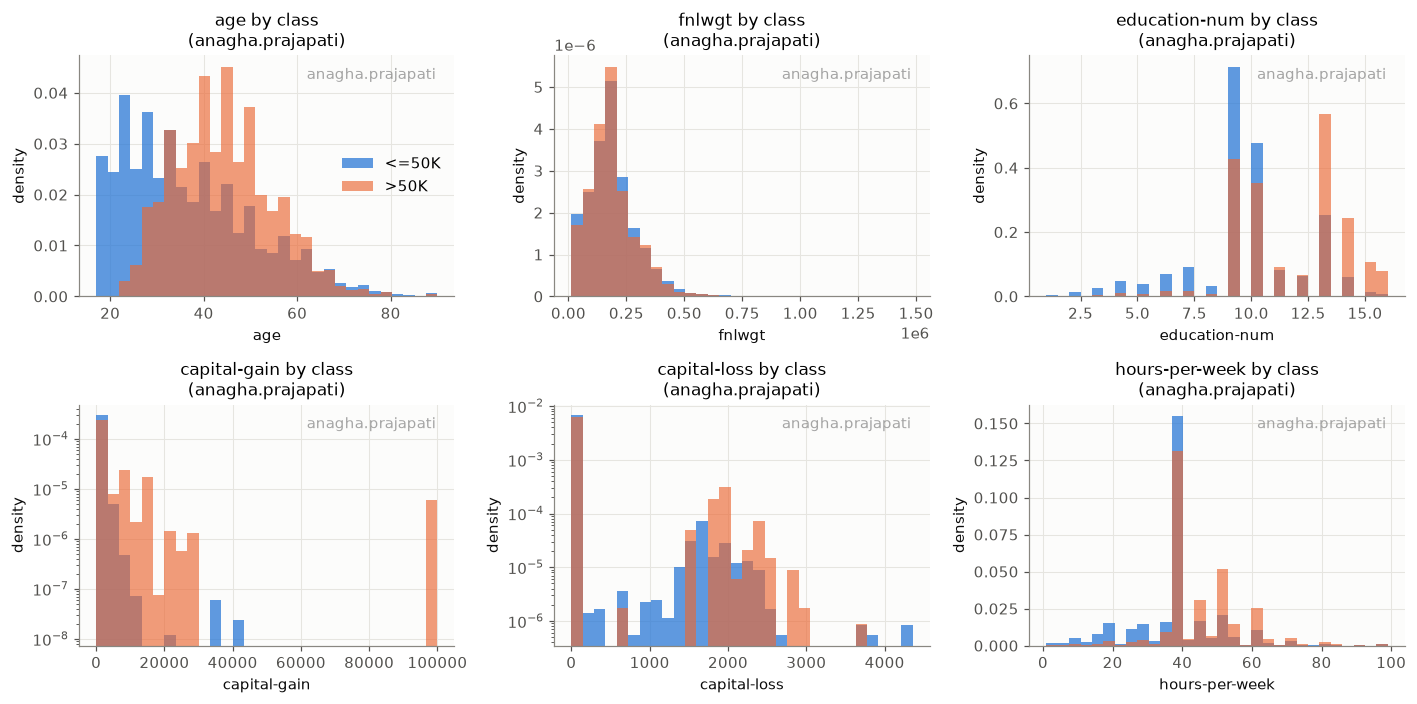

In [6]:
# distributions of the numerical features, split by class (development data)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, col in zip(axes.ravel(), NUMERICAL):
    data = [dev_df.loc[dev_df[TARGET] == c, col] for c in ["<=50K", ">50K"]]
    bins = np.histogram_bin_edges(dev_df[col], bins=30)
    ax.hist(data[0], bins=bins, color=BLUE, alpha=0.75, label="<=50K", density=True)
    ax.hist(data[1], bins=bins, color=ORANGE, alpha=0.65, label=">50K", density=True)
    ax.set_xlabel(col)
    ax.set_ylabel("density")
    if col in ("capital-gain", "capital-loss"):
        ax.set_yscale("log")
    titled(ax, f"{col} by class")
axes[0, 0].legend(loc="center right")
finish(fig, "1_1_1_numerical_histograms")

### Missing values: analysis and chosen strategy

The analysis below shows how the missing values are structured before a strategy is chosen.

In [7]:
miss_flags = dev_df[["workclass", "occupation", "native-country"]].isna()
any_missing = miss_flags.any(axis=1)
print(f"rows of adult.data with >= 1 missing value: {any_missing.sum()} ({any_missing.mean():.2%})")
print(f"workclass and occupation both missing     : {(miss_flags.workclass & miss_flags.occupation).sum()}")
only_occ = miss_flags.occupation & ~miss_flags.workclass
print(f"occupation missing but workclass present  : {only_occ.sum()} -> workclass = "
      f"{dev_df.loc[only_occ, 'workclass'].value_counts().to_dict()}")
print(f"P(>50K | row has a missing value) = {(dev_df.loc[any_missing, TARGET] == POSITIVE).mean():.3f}")
print(f"P(>50K | row is complete)         = {(dev_df.loc[~any_missing, TARGET] == POSITIVE).mean():.3f}")
print(f"missing values in numerical features: {int(dev_df[NUMERICAL].isna().sum().sum())}")

rows of adult.data with >= 1 missing value: 2399 (7.37%)
workclass and occupation both missing     : 1836
occupation missing but workclass present  : 7 -> workclass = {'Never-worked': 7}
P(>50K | row has a missing value) = 0.139
P(>50K | row is complete)         = 0.249
missing values in numerical features: 0


**Exploration summary**

* `adult.data` has 32,561 rows and `adult.test` has 16,281 rows, giving 48,842 in total. Each has 15 columns: 14 input features and the target `income`.
* There are **6 numerical** features (`int64`): `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`.
* There are **8 categorical** features (string): `workclass` (8 categories excluding missing), `education` (16), `marital-status` (7), `occupation` (14), `relationship` (6), `race` (5), `sex` (2), `native-country` (41 in combined data).
* **Missing values** occur only in three categorical features: `workclass`, `occupation` and `native-country` (exact counts in the table above). No numerical feature has missing values.
* **Classes are imbalanced:** about 76% `<=50K` and 24% `>50K`, with almost the same proportions in both files. A model that always predicts `<=50K` already reaches ≈76% accuracy, so this is the baseline to beat.

**Missing-value strategy: mode imputation, with the mode computed from the training split only.**

Justification:
1. Only ≈7.4% of rows are affected, and only in three categorical features. Dropping these rows is not acceptable: we would lose data, and we must produce a prediction for *every* test individual, so test rows cannot be dropped.
2. A tree splits on one-hot indicator columns, so every missing value needs *some* category. The most frequent category (`Private`, `Prof-specialty`, `United-States` in our training split) is the single most probable value for an unknown entry, so it is the least disruptive fill for a categorical feature.
3. To avoid **data leakage**, the modes are computed **only from the training split** (after the stratified split in 1.1.3) and then applied unchanged to the train, validation and test sets.

We note one reasonable alternative: keeping `"?"` as its own *Unknown* category. The analysis shows missingness is somewhat informative (rows with a missing value have a lower >50K rate). We prefer mode imputation because it matches the assignment's request to impute with training statistics and keeps the feature space smaller. `workclass` and `occupation` are almost always missing together, and the 7 rows with only `occupation` missing are `Never-worked` people.

## 1.1.2 Redundant Features

We implement the Pearson correlation from scratch, $r_{jk} = \frac{\sum_i (x_{ij}-\bar x_j)(x_{ik}-\bar x_k)}{\sqrt{\sum_i (x_{ij}-\bar x_j)^2}\sqrt{\sum_i (x_{ik}-\bar x_k)^2}}$, and apply it to the numerical features of the development data. The test set is never used. We also check the categorical ↔ numerical pair `education` / `education-num`, which encode the same concept.

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000,-0.077,0.037,0.078,0.058,0.069
fnlwgt,-0.077,1.000,-0.043,0.000,-0.010,-0.019
education-num,0.037,-0.043,1.000,0.123,0.080,0.148
capital-gain,0.078,0.000,0.123,1.000,-0.032,0.078
capital-loss,0.058,-0.010,0.080,-0.032,1.000,0.054
hours-per-week,0.069,-0.019,0.148,0.078,0.054,1.000


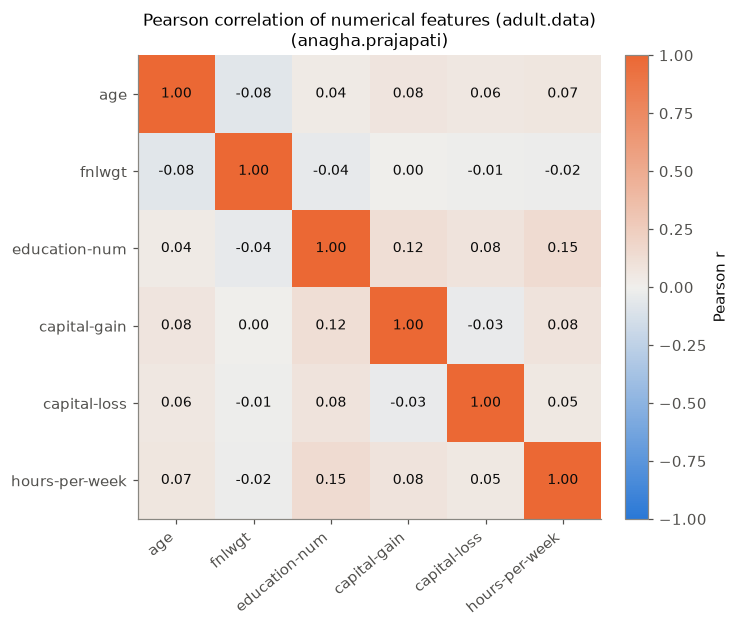

Numerical feature pairs ranked by |r|:
  education-num   - hours-per-week : r = +0.148
  education-num   - capital-gain   : r = +0.123
  education-num   - capital-loss   : r = +0.080
  capital-gain    - hours-per-week : r = +0.078
  age             - capital-gain   : r = +0.078
  age             - fnlwgt         : r = -0.077
  age             - hours-per-week : r = +0.069
  age             - capital-loss   : r = +0.058
  capital-loss    - hours-per-week : r = +0.054
  fnlwgt          - education-num  : r = -0.043
  age             - education-num  : r = +0.037
  capital-gain    - capital-loss   : r = -0.032
  fnlwgt          - hours-per-week : r = -0.019
  fnlwgt          - capital-loss   : r = -0.010
  fnlwgt          - capital-gain   : r = +0.000

Pairs with |r| >= 0.5 (strongly correlated): none


,r with target (>50K = 1)
age,0.234
fnlwgt,-0.009
education-num,0.335
capital-gain,0.223
capital-loss,0.151
hours-per-week,0.230


In [8]:
def pearson_corr_matrix(X):
    """Pearson correlation between the columns of X (from scratch)."""
    X = np.asarray(X, dtype=np.float64)
    Xc = X - X.mean(axis=0)
    norms = np.sqrt((Xc ** 2).sum(axis=0))
    return (Xc.T @ Xc) / np.outer(norms, norms)


corr = pearson_corr_matrix(dev_df[NUMERICAL].values)
assert np.allclose(corr, np.corrcoef(dev_df[NUMERICAL].values, rowvar=False))  # sanity check
corr_df = pd.DataFrame(corr, index=NUMERICAL, columns=NUMERICAL)
display(corr_df.round(3))

fig, ax = plt.subplots(figsize=(7, 5.8))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERICAL)), NUMERICAL, rotation=40, ha="right")
ax.set_yticks(range(len(NUMERICAL)), NUMERICAL)
ax.grid(False)
for i in range(len(NUMERICAL)):
    for j in range(len(NUMERICAL)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=9, color=INK)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
titled(ax, "Pearson correlation of numerical features (adult.data)")
finish(fig, "1_1_2_pearson_correlation")

off = [(NUMERICAL[i], NUMERICAL[j], corr[i, j]) for i in range(len(NUMERICAL)) for j in range(i + 1, len(NUMERICAL))]
off.sort(key=lambda t: -abs(t[2]))
print("Numerical feature pairs ranked by |r|:")
for a, b, r in off:
    print(f"  {a:15s} - {b:15s}: r = {r:+.3f}")
print(f"\nPairs with |r| >= 0.5 (strongly correlated): {[(a, b) for a, b, r in off if abs(r) >= 0.5] or 'none'}")

y_dev_binary = (dev_df[TARGET] == POSITIVE).astype(float).values
target_corr = pd.Series([pearson_corr_matrix(np.c_[dev_df[c].values, y_dev_binary])[0, 1] for c in NUMERICAL],
                        index=NUMERICAL, name="r with target (>50K = 1)")
display(target_corr.round(3).to_frame())

,nunique,min,max,count
education,,,,
Preschool,1,1,1,51
1st-4th,1,2,2,168
5th-6th,1,3,3,333
7th-8th,1,4,4,646
9th,1,5,5,514
10th,1,6,6,933
11th,1,7,7,1175
12th,1,8,8,433
HS-grad,1,9,9,10501


distinct education-num values per education category : [1]
distinct education categories per education-num value: [1]


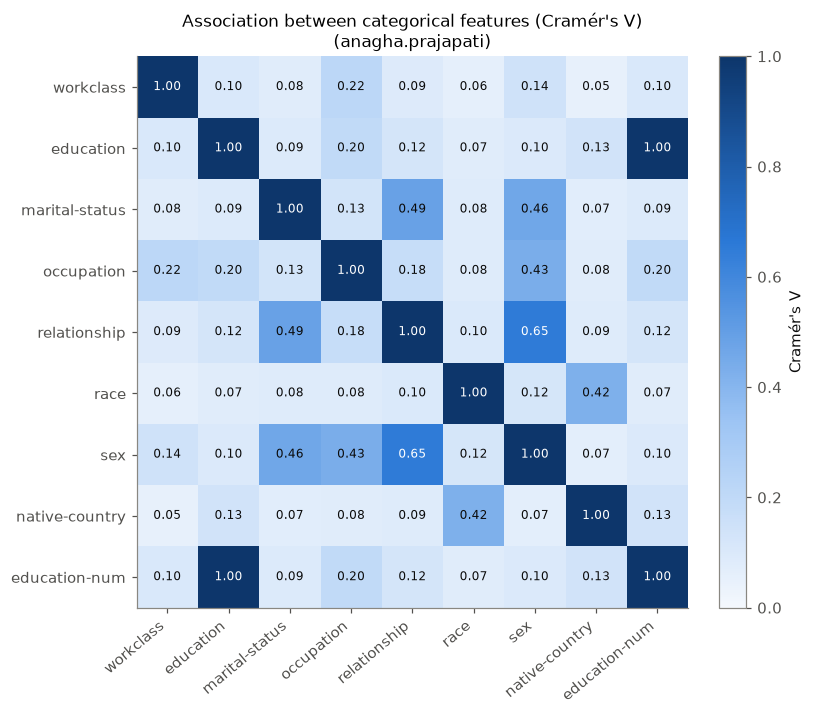

In [9]:
# education (categorical) vs education-num (numerical): is one a re-coding of the other?
edu_map = dev_df.groupby("education")["education-num"].agg(["nunique", "min", "max", "count"]).sort_values("min")
display(edu_map)
print("distinct education-num values per education category :", edu_map["nunique"].unique())
print("distinct education categories per education-num value:",
      dev_df.groupby("education-num")["education"].nunique().unique())


def cramers_v(a, b):
    """Cramér's V association between two categorical variables (chi-square computed from scratch)."""
    table = pd.crosstab(a, b).values.astype(float)
    n = table.sum()
    expected = np.outer(table.sum(1), table.sum(0)) / n
    chi2 = ((table - expected) ** 2 / expected).sum()
    r, k = table.shape
    return math.sqrt(chi2 / (n * (min(r, k) - 1)))


assoc_cols = CATEGORICAL + ["education-num"]
V = np.array([[cramers_v(dev_df[a], dev_df[b]) for b in assoc_cols] for a in assoc_cols])
fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = ax.imshow(V, cmap=SEQUENTIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(assoc_cols)), assoc_cols, rotation=40, ha="right")
ax.set_yticks(range(len(assoc_cols)), assoc_cols)
ax.grid(False)
for i in range(len(assoc_cols)):
    for j in range(len(assoc_cols)):
        ax.text(j, i, f"{V[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if V[i, j] > 0.6 else INK)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Cramér's V")
titled(ax, "Association between categorical features (Cramér's V)")
finish(fig, "1_1_2_cramers_v")

**Discussion: redundancy**

* **Numerical features:** none of the Pearson correlations is strong. The largest |r| is only ≈0.15 (`education-num`–`hours-per-week`), followed by 0.12 (`education-num`–`capital-gain`), far below any usual redundancy threshold (|r| ≥ 0.5–0.8). Every numerical feature therefore carries largely *independent* linear information, and **no numerical feature is removed**.
  `fnlwgt` (a census sampling weight) has essentially zero correlation with the target. It is weakly *relevant* but not *redundant*, so we keep it and let the trees decide; the feature-importance section (1.7) revisits it.
* **`education` vs `education-num`: perfectly redundant.** Each of the 16 education categories maps to exactly one `education-num` value and vice versa (Cramér's V = 1.00). `education-num` is simply an ordinal re-coding of `education`. Keeping both would add 16 one-hot columns that duplicate a single numerical column. **We remove the categorical feature `education`** and keep `education-num`. Its natural ordering lets a tree express "education ≥ Bachelors" with one threshold instead of several one-hot splits.
* Other categorical pairs are associated but **not** redundant: `relationship`–`sex` and `relationship`–`marital-status` (for example, `Husband` implies `Male` and married), and `race`–`native-country`. Neither feature of such a pair is a function of the other, so each carries extra information, and both are kept.

**Features used from here on:** 13 raw features (6 numerical + 7 categorical). The number of model features `p` after one-hot encoding is fixed in 1.1.4 and used consistently in all Random-Forest experiments.

In [10]:
DROPPED_FEATURES = ["education"]
CAT_USED = [c for c in CATEGORICAL if c not in DROPPED_FEATURES]
print("numerical features  :", NUMERICAL)
print("categorical features:", CAT_USED)
print("removed (redundant) :", DROPPED_FEATURES)

numerical features  : ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
categorical features: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
removed (redundant) : ['education']


## 1.1.3 Train / Validation / Test Split

`adult.test` is the final test set. `adult.data` is split **80% / 20%, stratified by the target**, with a from-scratch routine: inside each class the indices are shuffled with the seeded generator, and 20% of that class goes to validation. Both splits therefore keep the class proportions of `adult.data`.

In [11]:
def stratified_split(y, val_fraction, rng):
    """Return (train_idx, val_idx); every class is split with the same proportion."""
    train_parts, val_parts = [], []
    for c in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == c))
        n_val = int(round(val_fraction * len(idx)))
        val_parts.append(idx[:n_val])
        train_parts.append(idx[n_val:])
    return np.sort(np.concatenate(train_parts)), np.sort(np.concatenate(val_parts))


y_dev_all = (dev_df[TARGET] == POSITIVE).astype(np.int64).values
train_idx, val_idx = stratified_split(y_dev_all, 0.20, np.random.default_rng(SEED))
assert len(np.intersect1d(train_idx, val_idx)) == 0 and len(train_idx) + len(val_idx) == len(dev_df)

train_raw = dev_df.iloc[train_idx].reset_index(drop=True)
val_raw = dev_df.iloc[val_idx].reset_index(drop=True)
test_raw = test_df.copy()

split_rows = []
for name, df in [("train", train_raw), ("validation", val_raw), ("test", test_raw)]:
    n_pos = int((df[TARGET] == POSITIVE).sum())
    split_rows.append({"split": name, "samples": len(df), "share of all data": f"{len(df) / len(full_df):.1%}",
                       "n(<=50K)": len(df) - n_pos, "n(>50K)": n_pos,
                       "prop(<=50K)": round(1 - n_pos / len(df), 4), "prop(>50K)": round(n_pos / len(df), 4)})
split_table = pd.DataFrame(split_rows).set_index("split")
display(split_table)

,samples,share of all data,n(<=50K),n(>50K),prop(<=50K),prop(>50K)
split,,,,,,
train,26049,53.3%,19776,6273,0.7592,0.2408
validation,6512,13.3%,4944,1568,0.7592,0.2408
test,16281,33.3%,12435,3846,0.7638,0.2362


**Missing-value imputation (statistics from the training split only).** `ModeImputer.fit` sees only `train_raw`. The learned modes are then used to fill the validation and test sets.

In [12]:
class ModeImputer:
    """Fills missing categorical values with the most frequent category of the TRAINING data."""

    def fit(self, df, columns):
        self.modes_ = {c: df[c].value_counts().idxmax() for c in columns}
        return self

    def transform(self, df):
        df = df.copy()
        for c, mode in self.modes_.items():
            df[c] = df[c].fillna(mode)
        return df


imputer = ModeImputer().fit(train_raw, CAT_USED)
print("Training-set modes used for imputation:")
for c in ["workclass", "occupation", "native-country"]:
    print(f"  {c:15s} -> {imputer.modes_[c]!r}")
for name, df in [("train", train_raw), ("validation", val_raw), ("test", test_raw)]:
    print(f"missing values filled in {name:10s}: {int(df[CAT_USED].isna().sum().sum())}")

train_imp = imputer.transform(train_raw)
val_imp = imputer.transform(val_raw)
test_imp = imputer.transform(test_raw)
assert not any(d[NUMERICAL + CAT_USED].isna().any().any() for d in (train_imp, val_imp, test_imp))

Training-set modes used for imputation:
  workclass       -> 'Private'
  occupation      -> 'Prof-specialty'
  native-country  -> 'United-States'
missing values filled in train     : 3379
missing values filled in validation: 883
missing values filled in test      : 2203


## 1.1.4 Categorical Encoding (one-hot, fitted on the training split)

`OneHotEncoderScratch.fit` determines the category list of every categorical feature **from the training split only**. `transform` then builds the same columns for any data set: one 0/1 indicator per training category. A category that never appears in the training data (for example a rare country that falls in validation or test) becomes an all-zero block, so validation and test information never changes the representation. Numerical features are passed through unchanged. Trees are invariant to monotone transformations, so no scaling is needed.

In [13]:
class OneHotEncoderScratch:
    def __init__(self, numerical, categorical):
        self.numerical, self.categorical = list(numerical), list(categorical)

    def fit(self, df):
        self.categories_ = {c: sorted(df[c].unique()) for c in self.categorical}  # training categories only
        self.feature_names_ = list(self.numerical) + [f"{c}={v}" for c in self.categorical for v in self.categories_[c]]
        self.feature_groups_ = list(self.numerical) + [c for c in self.categorical for _ in self.categories_[c]]
        return self

    def transform(self, df):
        blocks = [df[self.numerical].to_numpy(dtype=np.float64)]
        for c in self.categorical:
            cats = np.array(self.categories_[c], dtype=object)
            blocks.append((df[c].to_numpy(dtype=object)[:, None] == cats[None, :]).astype(np.float64))
        return np.hstack(blocks)

    def unseen_counts(self, df):
        return {c: int((~df[c].isin(self.categories_[c])).sum()) for c in self.categorical}


encoder = OneHotEncoderScratch(NUMERICAL, CAT_USED).fit(train_imp)
X_train, X_val, X_test = (encoder.transform(d) for d in (train_imp, val_imp, test_imp))
y_train, y_val, y_test = ((d[TARGET] == POSITIVE).astype(np.int64).to_numpy() for d in (train_imp, val_imp, test_imp))
FEATURE_NAMES = encoder.feature_names_
FEATURE_GROUPS = encoder.feature_groups_
p = X_train.shape[1]

block_sizes = pd.Series({**{c: 1 for c in NUMERICAL}, **{c: len(v) for c, v in encoder.categories_.items()}},
                        name="model columns")
display(block_sizes.to_frame().T)
print("rows with a category unseen in training -> validation:",
      {k: v for k, v in encoder.unseen_counts(val_imp).items() if v}, "| test:",
      {k: v for k, v in encoder.unseen_counts(test_imp).items() if v})
print(f"\nX_train {X_train.shape}, X_val {X_val.shape}, X_test {X_test.shape}")
print(f"Final number of features after preprocessing: p = {p} "
      f"({len(NUMERICAL)} numerical + {p - len(NUMERICAL)} one-hot columns from {len(CAT_USED)} categorical features)")

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass,marital-status,occupation,relationship,race,sex,native-country
model columns,1,1,1,1,1,1,8,7,14,6,5,2,40


rows with a category unseen in training -> validation: {'native-country': 1} | test: {}

X_train (26049, 88), X_val (6512, 88), X_test (16281, 88)
Final number of features after preprocessing: p = 88 (6 numerical + 82 one-hot columns from 7 categorical features)


After preprocessing, every observation is described by **p = 88 numerical columns**: 6 numerical features plus 82 one-hot indicators (workclass 8, marital-status 7, occupation 14, relationship 6, race 5, sex 2, native-country 40). `native-country = Holand-Netherlands` occurs only once in `adult.data`. That row fell into the validation split, so the category is unknown to the training data and gets no column, exactly as required. This value of p defines the Random-Forest feature-subset sizes $m \in \{1, \sqrt p, p/2, p\}$ used later.

---
# 1.2 Decision Tree from Scratch

## 1.2.1 Finding the Best Split

**Split quality.** For a node with $n$ samples and positive-class fraction $\pi$:
* Gini impurity: $G(\pi) = 1-\pi^2-(1-\pi)^2 = 2\pi(1-\pi)$
* Entropy: $H(\pi) = -\pi\log_2\pi-(1-\pi)\log_2(1-\pi)$

A split into a left child with $n_L$ samples and a right child with $n_R$ samples is scored by the **weighted child impurity** $\frac{n_L}{n} I(\pi_L) + \frac{n_R}{n} I(\pi_R)$. The best split minimises it, which is the same as maximising the impurity decrease $I(\pi) - \frac{n_L}{n} I(\pi_L) - \frac{n_R}{n} I(\pi_R)$.

**Candidate thresholds.** For every feature the node's values are sorted, and the candidate thresholds are the **midpoints between consecutive sorted unique values**. The rule is "go left if $x_f \le t$". One-hot columns have only the values {0, 1}, so their single candidate is $t = 0.5$.

Two implementations are given:
1. `find_best_split_reference` follows the four steps of the assignment literally, with Python loops: (1) divide the observations, (2) compute the split quality, (3) reject splits with an empty child, (4) keep the best valid split. It is clear but slow.
2. `find_best_split` is the **vectorised** version used by the tree. It sorts each candidate feature once. Prefix sums of the sorted labels then give the class counts of the left child for *every* threshold in one pass, so all candidate splits of all candidate features are scored at once. A threshold can only lie between two *different* sorted values. With `min_samples_leaf ≥ 1`, this means splits with an empty child, or a child below the minimum leaf size, are rejected.

Both use the same tie-breaking rule (first feature in candidate order, then smallest threshold). The test below checks that they return exactly the same split on many random nodes.

In [14]:
def gini_impurity(pi):
    """Gini impurity of a binary node with positive fraction pi (element-wise)."""
    return 2.0 * pi * (1.0 - pi)


def entropy_impurity(pi):
    """Entropy (bits) of a binary node with positive fraction pi (element-wise, 0*log0 = 0)."""
    pi = np.asarray(pi, dtype=np.float64)
    q = 1.0 - pi
    with np.errstate(divide="ignore", invalid="ignore"):
        return -(np.where(pi > 0, pi * np.log2(pi), 0.0) + np.where(q > 0, q * np.log2(q), 0.0))


IMPURITY = {"gini": gini_impurity, "entropy": entropy_impurity}


def find_best_split_reference(X, y, features, criterion="gini", min_samples_leaf=1):
    """Literal (slow) implementation of the split search. Returns (j, threshold, weighted child impurity) or None,
    where j is the position of the chosen feature inside `features`."""
    imp = IMPURITY[criterion]
    n = len(y)
    n_pos = float(y.sum())
    best = None
    for j, f in enumerate(features):
        x = X[:, f]
        values = np.unique(x)                              # sorted unique values
        for t in (values[:-1] + values[1:]) / 2:           # candidate thresholds = midpoints
            left = x <= t                                  # (1) divide into two children
            n_l = int(left.sum())
            n_r = n - n_l
            if n_l == 0 or n_r == 0:                       # (3) reject an empty child
                continue
            if n_l < min_samples_leaf or n_r < min_samples_leaf:
                continue
            pos_l = float(y[left].sum())
            q = (n_l * imp(pos_l / n_l) + n_r * imp((n_pos - pos_l) / n_r)) / n   # (2) split quality
            if best is None or q < best[2]:                # (4) retain the best valid split
                best = (j, float(t), float(q))
    return best


def find_best_split(Xc, y, criterion="gini", min_samples_leaf=1):
    """Vectorised exhaustive split search.

    Xc : (m, n) array, values of the m candidate features for the n samples at the node
    y  : (n,) labels in {0, 1}
    Returns (j, threshold, weighted child impurity) of the best valid split, or None if no valid split exists.
    """
    imp = IMPURITY[criterion]
    m, n = Xc.shape
    msl = max(1, min_samples_leaf)
    order = np.argsort(Xc, axis=1, kind="stable")          # sort every candidate feature
    x_sorted = Xc[np.arange(m)[:, None], order]
    # position i <-> left child = the first i+1 sorted samples, threshold = midpoint of x_sorted[i], x_sorted[i+1]
    n_left = np.arange(1, n)
    n_right = n - n_left
    valid = x_sorted[:, 1:] > x_sorted[:, :-1]               # threshold must separate two distinct values
    valid &= (n_left >= msl) & (n_right >= msl)              # rejects empty children and too-small leaves
    jj, ii = np.nonzero(valid)
    if jj.size == 0:
        return None                                          # no valid split
    pos_cum = np.cumsum(y[order], axis=1)                    # positives among the first i+1 sorted samples
    pos_l = pos_cum[jj, ii].astype(np.float64)
    n_l = n_left[ii]
    n_r = n - n_l
    q = (n_l * imp(pos_l / n_l) + n_r * imp((float(y.sum()) - pos_l) / n_r)) / n
    k = int(np.argmin(q))                                    # retain the best valid split
    j, i = jj[k], ii[k]
    return int(j), float((x_sorted[j, i] + x_sorted[j, i + 1]) / 2), float(q[k])

In [15]:
# A tiny hand-checkable example: one feature, 6 samples
x_toy = np.array([[1.0], [2.0], [2.0], [3.0], [4.0], [5.0]])
y_toy = np.array([0, 0, 0, 1, 1, 1])
print("toy example (reference) :", find_best_split_reference(x_toy, y_toy, [0]))
print("toy example (vectorised):", find_best_split(x_toy.T, y_toy))
print("-> threshold 2.5 separates the classes perfectly, weighted child impurity 0\n")

# Equivalence test of the two implementations on random nodes of the real training data
test_rng = np.random.default_rng(SEED)
n_checks = 0
for trial in range(40):
    rows = test_rng.choice(len(y_train), size=int(test_rng.integers(20, 1500)), replace=False)
    feats = test_rng.choice(p, size=int(test_rng.integers(1, p + 1)), replace=False)
    criterion = ["gini", "entropy"][trial % 2]
    msl = [1, 5, 20][trial % 3]
    ref = find_best_split_reference(X_train[rows], y_train[rows], feats, criterion, msl)
    vec = find_best_split(X_train[rows][:, feats].T, y_train[rows], criterion, msl)
    assert (ref is None) == (vec is None)
    if ref is not None:
        assert ref[0] == vec[0] and ref[1] == vec[1] and np.isclose(ref[2], vec[2]), (ref, vec)
    n_checks += 1
print(f"Vectorised split search == literal reference implementation on all {n_checks} random nodes.")

toy example (reference) : (0, 2.5, 0.0)
toy example (vectorised): (0, 2.5, 0.0)
-> threshold 2.5 separates the classes perfectly, weighted child impurity 0



Vectorised split search == literal reference implementation on all 40 random nodes.


## 1.2.2 Implementation

**`TreeNode`.** An *internal* node stores `feature`, `threshold`, `left` (samples with $x_{feature} \le threshold$) and `right`. Every node also stores `prediction` (the **majority class** of the training samples reaching it; an exact tie goes to class 0, `<=50K`, the overall majority class), its sample count, its impurity, the impurity decrease of its split (used for feature importance) and, for a leaf, the reason it stopped.

**`DecisionTree`.** The tree grows recursively from the root. A node becomes a **leaf** when:
1. all its samples belong to the same class (`pure`);
2. the maximum depth is reached (`max_depth`);
3. it has too few samples to split: fewer than `min_samples_split`, or fewer than `2 × min_samples_leaf` (`too_few_samples`);
4. no valid split exists, because every feature is constant in the node or every threshold would violate the leaf-size limit (`no_valid_split`).

Otherwise the best split is found with `find_best_split`, and the two children are grown recursively.

**Random feature selection (needed for Random Forests, 1.4).** `max_features = m` limits the split search at **every node** to `m` features drawn **at random for that node** (`_candidate_features`). A fresh random permutation is drawn at every node, so the subsets are independent from node to node. A feature that is constant inside the node can never produce a valid split. As in the standard Breiman/CART implementations, such features are skipped and drawing continues in the same random order until `m` non-constant features are found. A feature found constant at a node is constant in all its descendants, so it is dropped from the descendants' candidate list. This is purely a speed-up and does not change the result. With `max_features=None` all features are searched, which is the ordinary CART tree used in 1.2 and for bagging.

**Prediction.** After fitting, the linked `TreeNode` structure is also flattened into arrays (`feature_`, `threshold_`, `left_`, `right_`, `value_`), so many rows can be routed through the tree at once with NumPy (`predict`). `predict_one` walks the `TreeNode` objects for a single sample. Both give identical results (checked below).

In [16]:
class TreeNode:
    """One node of a binary decision tree."""
    __slots__ = ("feature", "threshold", "left", "right", "prediction", "n_samples", "n_pos",
                 "impurity", "impurity_decrease", "depth", "leaf_reason")

    def __init__(self, depth, n_samples, n_pos, impurity):
        self.feature = None          # index of the split feature   (internal nodes)
        self.threshold = None        # go left if x[feature] <= threshold
        self.left = None             # TreeNode
        self.right = None            # TreeNode
        self.depth = depth
        self.n_samples = n_samples
        self.n_pos = n_pos
        self.impurity = impurity
        self.prediction = int(2 * n_pos > n_samples)   # majority class (exact tie -> 0)
        self.impurity_decrease = 0.0
        self.leaf_reason = None

    @property
    def is_leaf(self):
        return self.left is None

    def __repr__(self):
        if self.is_leaf:
            return f"Leaf(pred={self.prediction}, n={self.n_samples}, reason={self.leaf_reason})"
        return f"Node(x[{self.feature}] <= {self.threshold:.4g}, n={self.n_samples})"


def resolve_max_features(max_features, n_features):
    """Number m of candidate features per node."""
    if max_features is None or max_features == "all":
        return n_features
    if max_features == "sqrt":
        return max(1, int(round(math.sqrt(n_features))))
    if max_features == "half":
        return max(1, n_features // 2)
    if isinstance(max_features, float):
        return max(1, int(round(max_features * n_features)))
    return int(min(max(1, max_features), n_features))


class DecisionTree:
    """Binary CART classification tree for labels {0, 1}, implemented from scratch."""

    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1, criterion="gini",
                 max_features=None, random_state=None, keep_nodes=True):
        assert criterion in IMPURITY
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.criterion = criterion
        self.max_features = max_features
        self.random_state = random_state
        self.keep_nodes = keep_nodes   # False: forests keep only the compact array form

    # ------------------------------------------------------------------ fitting
    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=np.int64)
        n, n_features = X.shape
        self.n_features_ = n_features
        self.max_features_ = resolve_max_features(self.max_features, n_features)
        self._rng = (self.random_state if isinstance(self.random_state, np.random.Generator)
                     else np.random.default_rng(self.random_state))
        self._impurity = IMPURITY[self.criterion]
        self._XT = np.ascontiguousarray(X.T)      # feature-major copy -> fast gathers of a feature at a node
        self._y = y
        self._n_root = n
        self.impurity_decrease_ = np.zeros(n_features)   # sum of weighted impurity decreases per feature
        self.n_values_examined_ = 0                      # feature values read during split search (cost measure)
        self.root = self._grow(np.arange(n), 0, np.arange(n_features))
        self._flatten()
        del self._XT, self._y, self._rng, self._impurity
        if not self.keep_nodes:
            self.root = None
        return self

    def _make_leaf(self, node, reason):
        node.leaf_reason = reason
        return node

    def _grow(self, idx, depth, active):
        y = self._y[idx]
        n = idx.size
        n_pos = int(y.sum())
        node = TreeNode(depth, n, n_pos, float(self._impurity(n_pos / n)))

        # ---- stopping conditions
        if n_pos == 0 or n_pos == n:
            return self._make_leaf(node, "pure")
        if self.max_depth is not None and depth >= self.max_depth:
            return self._make_leaf(node, "max_depth")
        if n < self.min_samples_split or n < 2 * self.min_samples_leaf:
            return self._make_leaf(node, "too_few_samples")

        # ---- (random) candidate features for THIS node, then best split among them
        feats, values, active = self._candidate_features(idx, active)
        if feats.size == 0:
            return self._make_leaf(node, "no_valid_split")
        split = find_best_split(values, y, self.criterion, self.min_samples_leaf)
        if split is None:
            return self._make_leaf(node, "no_valid_split")

        j, threshold, child_impurity = split
        node.feature = int(feats[j])
        node.threshold = threshold
        # weighted impurity decrease  (n_t / N) * (I(t) - weighted child impurity)
        node.impurity_decrease = (n / self._n_root) * (node.impurity - child_impurity)
        self.impurity_decrease_[node.feature] += node.impurity_decrease

        go_left = values[j] <= threshold
        node.left = self._grow(idx[go_left], depth + 1, active)
        node.right = self._grow(idx[~go_left], depth + 1, active)
        return node

    def _candidate_features(self, idx, active):
        """Draw up to m candidate features for one node (fresh random draw at EVERY node).

        Returns (feature ids, their values at the node as an (m', n) array, updated list of non-constant features).
        """
        m = min(self.max_features_, active.size)
        order = self._rng.permutation(active) if m < active.size else active
        values = self._XT[np.ix_(order[:m], idx)]
        self.n_values_examined_ += values.size
        nonconst = values.max(axis=1) > values.min(axis=1)
        feats, values, constant = order[:m][nonconst], values[nonconst], order[:m][~nonconst]
        if feats.size < m and m < order.size:
            # some drawn features are constant here -> keep drawing in the same random order
            rest = order[m:]
            rest_values = self._XT[np.ix_(rest, idx)]
            self.n_values_examined_ += rest_values.size
            rest_nonconst = rest_values.max(axis=1) > rest_values.min(axis=1)
            constant = np.concatenate([constant, rest[~rest_nonconst]])
            take = np.flatnonzero(rest_nonconst)[: m - feats.size]
            feats = np.concatenate([feats, rest[take]])
            values = np.vstack([values, rest_values[take]])
        if constant.size:
            active = np.setdiff1d(active, constant, assume_unique=True)  # constant in every descendant too
        return feats, values, active

    def _flatten(self):
        """Store the tree as arrays (breadth-first order) for fast vectorised prediction."""
        nodes, k = [self.root], 0
        while k < len(nodes):
            if not nodes[k].is_leaf:
                nodes.extend((nodes[k].left, nodes[k].right))
            k += 1
        index = {id(nd): i for i, nd in enumerate(nodes)}
        self.feature_ = np.array([-1 if nd.is_leaf else nd.feature for nd in nodes], dtype=np.int64)
        self.threshold_ = np.array([0.0 if nd.is_leaf else nd.threshold for nd in nodes])
        self.left_ = np.array([-1 if nd.is_leaf else index[id(nd.left)] for nd in nodes], dtype=np.int64)
        self.right_ = np.array([-1 if nd.is_leaf else index[id(nd.right)] for nd in nodes], dtype=np.int64)
        self.value_ = np.array([nd.prediction for nd in nodes], dtype=np.int64)
        self.n_node_samples_ = np.array([nd.n_samples for nd in nodes], dtype=np.int64)
        self.n_nodes_ = len(nodes)
        self.n_leaves_ = int((self.feature_ < 0).sum())
        self.depth_ = max(nd.depth for nd in nodes)                 # actual maximum depth
        self.used_features_ = np.unique(self.feature_[self.feature_ >= 0])
        self.leaf_reasons_ = pd.Series([nd.leaf_reason for nd in nodes if nd.is_leaf]).value_counts().to_dict()

    # ------------------------------------------------------------------ prediction
    def predict(self, X):
        """Route all rows through the tree simultaneously (one NumPy step per tree level)."""
        X = np.asarray(X, dtype=np.float64)
        node = np.zeros(X.shape[0], dtype=np.int64)
        active = np.flatnonzero(self.feature_[node] >= 0)
        while active.size:
            nd = node[active]
            go_left = X[active, self.feature_[nd]] <= self.threshold_[nd]
            node[active] = np.where(go_left, self.left_[nd], self.right_[nd])
            active = active[self.feature_[node[active]] >= 0]
        return self.value_[node]

    def predict_one(self, x):
        """Walk the TreeNode objects for a single sample."""
        node = self.root
        while not node.is_leaf:
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.prediction


def accuracy_score(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


def print_tree(node, names, max_depth=3, indent=""):
    """Text rendering of the top of a tree."""
    if node.is_leaf or node.depth >= max_depth:
        frac = node.n_pos / node.n_samples
        print(f"{indent}-> predict {'>50K' if node.prediction else '<=50K'}  (n={node.n_samples}, P(>50K)={frac:.2f})")
        return
    print(f"{indent}if {names[node.feature]} <= {node.threshold:.4g}:   (n={node.n_samples}, impurity={node.impurity:.3f})")
    print_tree(node.left, names, max_depth, indent + "    ")
    print(f"{indent}else:  # {names[node.feature]} > {node.threshold:.4g}")
    print_tree(node.right, names, max_depth, indent + "    ")

In [17]:
# ---- sanity checks of the implementation
# (a) a tiny dataset that needs two levels (y = x0 AND x1)
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]] * 5, dtype=float)
y_and = (X_and[:, 0] * X_and[:, 1]).astype(int)
t_and = DecisionTree().fit(X_and, y_and)
print("AND problem: depth", t_and.depth_, "| leaves", t_and.n_leaves_, "| train accuracy", accuracy_score(y_and, t_and.predict(X_and)))

# (b) a depth-3 tree on the census data: structure and stopping reasons
t3 = DecisionTree(max_depth=3, random_state=SEED).fit(X_train, y_train)
print_tree(t3.root, FEATURE_NAMES, max_depth=3)
print("leaf reasons:", t3.leaf_reasons_, "| nodes =", t3.n_nodes_, "= 2*leaves-1:", t3.n_nodes_ == 2 * t3.n_leaves_ - 1)

# (c) vectorised prediction == walking the TreeNode objects
t_full = DecisionTree(random_state=SEED).fit(X_train, y_train)
fast = t_full.predict(X_val)
slow = np.array([t_full.predict_one(x) for x in X_val])
print("\nunrestricted tree: predict() == predict_one() on all validation rows:", bool(np.all(fast == slow)))
print("unrestricted tree leaf reasons:", t_full.leaf_reasons_)

# (d) why training accuracy of the unrestricted tree is not exactly 1: identical rows with different labels
_, group_id = np.unique(X_train, axis=0, return_inverse=True)
group_size = np.bincount(group_id.ravel())
group_pos = np.bincount(group_id.ravel(), weights=y_train)
conflict = (group_pos > 0) & (group_pos < group_size)
conflict_rows = int(group_size[conflict].sum())
print(f"training rows in groups of identical feature vectors with conflicting labels: {conflict_rows}")
print(f"training accuracy of unrestricted tree: {accuracy_score(y_train, t_full.predict(X_train)):.5f}")

AND problem: depth 2 | leaves 3 | train accuracy 1.0


if marital-status=Married-civ-spouse <= 0.5:   (n=26049, impurity=0.366)
    if capital-gain <= 7140:   (n=14017, impurity=0.123)
        if education-num <= 13.5:   (n=13760, impurity=0.094)
            -> predict <=50K  (n=13031, P(>50K)=0.04)
        else:  # education-num > 13.5
            -> predict <=50K  (n=729, P(>50K)=0.26)
    else:  # capital-gain > 7140
        if age <= 21:   (n=257, impurity=0.082)
            -> predict <=50K  (n=4, P(>50K)=0.00)
        else:  # age > 21
            -> predict >50K  (n=253, P(>50K)=0.97)
else:  # marital-status=Married-civ-spouse > 0.5
    if education-num <= 12.5:   (n=12032, impurity=0.494)
        if capital-gain <= 5096:   (n=8458, impurity=0.441)
            -> predict <=50K  (n=8041, P(>50K)=0.29)
        else:  # capital-gain > 5096
            -> predict >50K  (n=417, P(>50K)=0.97)
    else:  # education-num > 12.5
        if capital-gain <= 5096:   (n=3574, impurity=0.403)
            -> predict >50K  (n=3043, P(>50K)=0.67)
  


unrestricted tree: predict() == predict_one() on all validation rows: True
unrestricted tree leaf reasons: {'pure': 3812, 'no_valid_split': 1}
training rows in groups of identical feature vectors with conflicting labels: 2
training accuracy of unrestricted tree: 0.99996


## 1.2.3 Tree Depth Experiment

Gini trees with `max_depth ∈ {1, 3, 5, 7, unrestricted}` (`min_samples_split=2`, `min_samples_leaf=1`) are trained on the training split and evaluated on train and validation. Training time is the wall-clock time of `fit`.

,train acc,val acc,leaves,actual max depth,train time (s),work (M values examined)
max_depth,,,,,,
1,0.7592,0.7592,2,1,0.141,2.3
3,0.8439,0.8435,8,3,0.291,6.7
5,0.8547,0.8530,29,5,0.531,10.9
7,0.8583,0.8526,76,7,0.997,14.9
unrestricted,1.0000,0.8153,3813,49,2.358,30.7


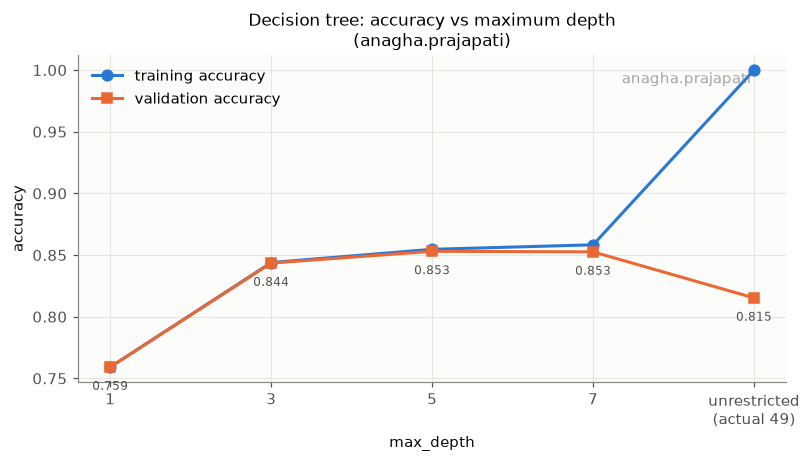

In [18]:
def fit_timed(model, X, y):
    t0 = time.perf_counter()
    model.fit(X, y)
    return model, time.perf_counter() - t0


depth_settings = [1, 3, 5, 7, None]
depth_rows, depth_trees = [], {}
for d in depth_settings:
    tree, t_fit = fit_timed(DecisionTree(max_depth=d, criterion="gini", random_state=SEED), X_train, y_train)
    depth_trees[d] = tree
    depth_rows.append({"max_depth": "unrestricted" if d is None else d,
                       "train acc": accuracy_score(y_train, tree.predict(X_train)),
                       "val acc": accuracy_score(y_val, tree.predict(X_val)),
                       "leaves": tree.n_leaves_, "actual max depth": tree.depth_, "train time (s)": t_fit,
                       "work (M values examined)": tree.n_values_examined_ / 1e6})
depth_table = pd.DataFrame(depth_rows).set_index("max_depth")
display(fmt(depth_table).format({"train acc": "{:.4f}", "val acc": "{:.4f}", "train time (s)": "{:.3f}",
                                 "work (M values examined)": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
xs = np.arange(len(depth_settings))
labels = [str(d) if d is not None else f"unrestricted\n(actual {depth_trees[None].depth_})" for d in depth_settings]
ax.plot(xs, depth_table["train acc"], "o-", color=BLUE, label="training accuracy")
ax.plot(xs, depth_table["val acc"], "s-", color=ORANGE, label="validation accuracy")
for x_, a in zip(xs, depth_table["val acc"]):
    ax.annotate(f"{a:.3f}", (x_, a), textcoords="offset points", xytext=(0, -15), ha="center", fontsize=8, color=INK2)
ax.set_xticks(xs, labels)
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.legend(loc="upper left")
titled(ax, "Decision tree: accuracy vs maximum depth")
finish(fig, "1_2_3_tree_depth_accuracy")

To choose the **best single tree** fairly for the comparison with the forest (1.4.4), we also sweep every depth from 1 to 20, plus the unrestricted tree, and select the depth with the highest validation accuracy.

   max_depth  train acc  val acc  leaves  time (s)
           1     0.7592   0.7592       2    0.1222
           2     0.8286   0.8266       4    0.2359
           3     0.8439   0.8435       8    0.3889
           4     0.8494   0.8478      15    0.5065
           5     0.8547   0.8530      29    0.6520
           6     0.8566   0.8523      49    0.6970
           7     0.8583   0.8526      76    0.8219
           8     0.8615   0.8523     116    0.9194
           9     0.8647   0.8540     178    1.0282
          10     0.8712   0.8601     255    0.9947
          11     0.8759   0.8567     354    1.1935
          12     0.8813   0.8524     484    1.3459
          13     0.8875   0.8515     636    1.4759
          14     0.8944   0.8492     797    1.6193
          15     0.9011   0.8464     976    1.7697
          16     0.9086   0.8441    1167    1.9729
          17     0.9153   0.8432    1363    1.8562
          18     0.9226   0.8383    1563    1.9440
          19     0.9302   0.835

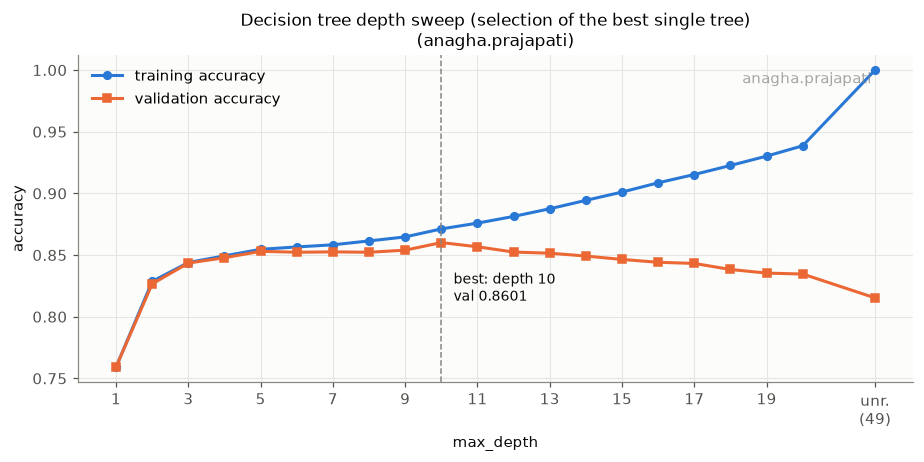

In [19]:
sweep_depths = list(range(1, 21)) + [None]
sweep_rows, sweep_trees = [], {}
for d in sweep_depths:
    tree, t_fit = fit_timed(DecisionTree(max_depth=d, random_state=SEED), X_train, y_train)
    sweep_trees[d] = tree
    sweep_rows.append({"max_depth": d, "train acc": accuracy_score(y_train, tree.predict(X_train)),
                       "val acc": accuracy_score(y_val, tree.predict(X_val)), "leaves": tree.n_leaves_,
                       "time (s)": t_fit})
sweep_table = pd.DataFrame(sweep_rows)
sweep_table["max_depth"] = ["unrestricted" if d is None else d for d in sweep_depths]
best_i = int(np.argmax(sweep_table["val acc"].values))          # first (shallowest) maximum
best_row = sweep_table.iloc[best_i]
BEST_TREE_DEPTH = sweep_depths[best_i]
best_tree = sweep_trees[BEST_TREE_DEPTH]
best_tree_time = float(best_row["time (s)"])
print(sweep_table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nBest single tree on validation: max_depth = {BEST_TREE_DEPTH}, val acc = {best_row['val acc']:.4f}, "
      f"leaves = {best_tree.n_leaves_}")

fig, ax = plt.subplots(figsize=(8.5, 4.3))
xs = np.array([d if d is not None else 22 for d in sweep_depths])
ax.plot(xs, sweep_table["train acc"], "o-", color=BLUE, label="training accuracy", markersize=5)
ax.plot(xs, sweep_table["val acc"], "s-", color=ORANGE, label="validation accuracy", markersize=5)
ax.axvline(BEST_TREE_DEPTH if BEST_TREE_DEPTH is not None else 22, color=MUTED, ls="--", lw=1)
ax.annotate(f"best: depth {BEST_TREE_DEPTH}\nval {best_row['val acc']:.4f}",
            (BEST_TREE_DEPTH if BEST_TREE_DEPTH is not None else 22, best_row["val acc"]),
            textcoords="offset points", xytext=(8, -38), fontsize=9, color=INK)
ax.set_xticks(list(range(1, 21, 2)) + [22], [str(v) for v in range(1, 21, 2)] + [f"unr.\n({sweep_trees[None].depth_})"])
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.legend(loc="upper left")
titled(ax, "Decision tree depth sweep (selection of the best single tree)")
finish(fig, "1_2_3_tree_depth_sweep")

**Discussion: tree depth**

* **Shallow trees underfit.** The depth-1 stump splits on `marital-status=Married-civ-spouse`. Even among married people fewer than half earn >50K, so *both* leaves predict `<=50K` and the accuracy is exactly the majority-class rate (75.92% on train and on validation). Training and validation accuracy are identical: the model is too simple (**high bias**, almost no variance).
* **Moderate depth is best.** Validation accuracy rises to 84.4% at depth 3 and 85.3% at depth 5, and stays there at depth 7 (85.3%). The full sweep peaks at **depth 10 (86.01%, 255 leaves)**. Beyond that, training accuracy keeps rising while validation accuracy falls steadily (83.5% at depth 20).
* **Unrestricted trees overfit.** Without a depth limit the tree grows 49 levels deep with 3,813 leaves and fits the training data almost perfectly (99.996%; the only training errors are 2 rows with identical features but different labels). Validation accuracy drops to 81.5%, *below the depth-3 tree*. The tree memorises noise (**high variance**): the train–validation gap grows from 0 to 18.5 percentage points.
* **Cost.** The number of leaves grows quickly with depth (2 → 8 → 29 → 76 → 3,813), and so do the split-search work and the training time. The work per level is roughly constant near the top (about 2 million values per level, because all nodes of one level together hold at most N samples) and shrinks further down as nodes become pure.
* **Caveat.** The validation set has 6,512 rows, so one accuracy value has a standard error of about 0.43 percentage points. The peak at depth 10 is only 0.3–0.6 points above its neighbours (depths 9 and 11), so the data support "a depth of roughly 5 to 11" more than they support depth 10 exactly.

## 1.2.4 Gini versus Entropy

Trees are otherwise identical: same data, same depth, `min_samples_split = 2` and `min_samples_leaf = 1`. The comparison is repeated for several depths (3, 7, 10 and unrestricted). Training time is the mean of 3 runs to reduce timing noise.

In [20]:
crit_rows, crit_trees = [], {}
for d in [3, 7, 10, None]:
    for crit in ["gini", "entropy"]:
        times = []
        for rep in range(3):
            tree, t_fit = fit_timed(DecisionTree(max_depth=d, criterion=crit, random_state=SEED), X_train, y_train)
            times.append(t_fit)
        crit_trees[(d, crit)] = tree
        crit_rows.append({"max_depth": "unrestricted" if d is None else d, "criterion": crit,
                          "train acc": accuracy_score(y_train, tree.predict(X_train)),
                          "val acc": accuracy_score(y_val, tree.predict(X_val)),
                          "leaves": tree.n_leaves_, "actual depth": tree.depth_,
                          "train time (s)": np.mean(times), "time std (s)": np.std(times)})
crit_table = pd.DataFrame(crit_rows)
display(fmt(crit_table).format({"train acc": "{:.4f}", "val acc": "{:.4f}", "train time (s)": "{:.3f}",
                                 "time std (s)": "{:.3f}"}).hide(axis="index"))

for d in [3, 7, 10, None]:
    agree = np.mean(crit_trees[(d, "gini")].predict(X_val) == crit_trees[(d, "entropy")].predict(X_val))
    root_g, root_e = crit_trees[(d, "gini")].root, crit_trees[(d, "entropy")].root
    print(f"max_depth={str(d):5s}: Gini/entropy agree on {agree:.2%} of validation predictions; root split "
          f"gini: {FEATURE_NAMES[root_g.feature]} | entropy: {FEATURE_NAMES[root_e.feature]}")

max_depth,criterion,train acc,val acc,leaves,actual depth,train time (s),time std (s)
3,gini,0.8439,0.8435,8,3,0.421,0.008
3,entropy,0.8439,0.8435,8,3,0.423,0.010
7,gini,0.8583,0.8526,76,7,0.921,0.014
7,entropy,0.8554,0.8538,73,7,0.936,0.086
10,gini,0.8712,0.8601,255,10,1.279,0.041
10,entropy,0.8644,0.8543,230,10,1.260,0.009
unrestricted,gini,1.0000,0.8153,3813,49,2.769,0.100
unrestricted,entropy,1.0000,0.8143,3694,57,3.182,0.114


max_depth=3    : Gini/entropy agree on 100.00% of validation predictions; root split gini: marital-status=Married-civ-spouse | entropy: marital-status=Married-civ-spouse
max_depth=7    : Gini/entropy agree on 98.80% of validation predictions; root split gini: marital-status=Married-civ-spouse | entropy: marital-status=Married-civ-spouse
max_depth=10   : Gini/entropy agree on 96.35% of validation predictions; root split gini: marital-status=Married-civ-spouse | entropy: marital-status=Married-civ-spouse
max_depth=None : Gini/entropy agree on 87.71% of validation predictions; root split gini: marital-status=Married-civ-spouse | entropy: marital-status=Married-civ-spouse


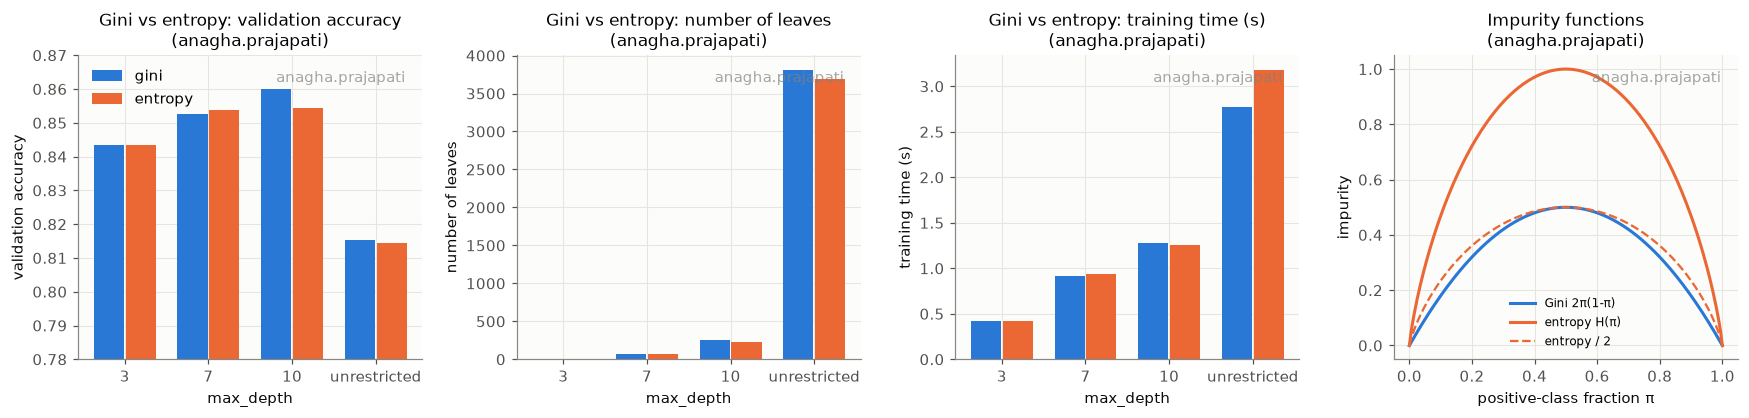

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
depth_labels = ["3", "7", "10", "unrestricted"]
xs = np.arange(4)
for ax, metric, ylabel in zip(axes[:3], ["val acc", "leaves", "train time (s)"],
                              ["validation accuracy", "number of leaves", "training time (s)"]):
    for k, (crit, color) in enumerate([("gini", BLUE), ("entropy", ORANGE)]):
        vals = crit_table.loc[crit_table["criterion"] == crit, metric].values
        ax.bar(xs + (k - 0.5) * 0.38, vals, width=0.36, color=color, label=crit)
    ax.set_xticks(xs, depth_labels)
    ax.set_xlabel("max_depth")
    ax.set_ylabel(ylabel)
    titled(ax, f"Gini vs entropy: {ylabel}")
axes[0].set_ylim(0.78, 0.87)
axes[0].legend(loc="upper left")
pi = np.linspace(0, 1, 201)
axes[3].plot(pi, gini_impurity(pi), color=BLUE, label="Gini 2π(1-π)")
axes[3].plot(pi, entropy_impurity(pi), color=ORANGE, label="entropy H(π)")
axes[3].plot(pi, entropy_impurity(pi) / 2, color=ORANGE, ls="--", lw=1.5, label="entropy / 2")
axes[3].set_xlabel("positive-class fraction π")
axes[3].set_ylabel("impurity")
axes[3].legend(loc="lower center", fontsize=8)
titled(axes[3], "Impurity functions")
finish(fig, "1_2_4_gini_vs_entropy")

**Discussion: Gini vs entropy**

* **Accuracy.** The two criteria perform almost the same. At depth 3 they build the *identical* tree (100% agreement). At depth 7 entropy is 0.1 points better on validation (85.38% vs 85.26%); at depth 10 Gini is 0.6 points better (86.01% vs 85.43%); unrestricted, they differ by 0.1 points (81.53% vs 81.43%). No direction is consistent, and all differences are within about one standard error (0.43 points) or slightly above it.
* **Why so similar.** The right-hand plot shows that entropy/2 and Gini are almost the same concave function of π, both maximal at π = 0.5, so they rank candidate splits almost identically. Both pick the same root split. Small ranking differences deep in the tree then compound: the criteria agree on 98.8% of validation predictions at depth 7, 96.4% at depth 10, and 87.7% for unrestricted trees. Yet the unrestricted accuracies are the same, which shows the disagreement is in the noisy, overfitted leaves.
* **Tree size.** Entropy gives slightly smaller trees here (73 vs 76 leaves at depth 7, 230 vs 255 at depth 10, 3,694 vs 3,813 unrestricted), but its unrestricted tree is deeper (57 vs 49 levels).
* **Training time.** At limited depth the times are within a few percent of each other. For the unrestricted tree, entropy was about 15% slower in this run (3.2 s vs 2.8 s). Entropy needs a logarithm for every candidate threshold, but most of the time goes into sorting and bookkeeping, which both criteria share, so the difference stays small.
* **Conclusion.** The choice of criterion matters far less than the choice of depth. We use **Gini** in the rest of the notebook: it is at least as accurate here and marginally cheaper to compute.

---
# 1.3 Bootstrap Sampling and Bagging

## 1.3.1 Bootstrap Sampling

A bootstrap sample of a data set with $N$ observations is made of $N$ indices, each drawn **uniformly at random with replacement** from $\{0,\dots,N-1\}$.

In [22]:
def bootstrap_sample(n, rng):
    """Indices of a bootstrap sample: n draws with replacement from {0, ..., n-1}."""
    return rng.integers(0, n, size=n)


N = len(y_train)
boot_rng = np.random.default_rng(SEED)
theory_finite = 1 - (1 - 1 / N) ** N
theory_limit = 1 - math.exp(-1)
boot_rows, multiplicities = [], []
for b in range(10):
    idx = bootstrap_sample(N, boot_rng)
    counts = np.bincount(idx, minlength=N)          # how many times each observation was drawn
    multiplicities.append(counts)
    n_unique = int((counts > 0).sum())
    boot_rows.append({"sample": b + 1, "unique selected": n_unique, "not selected (OOB)": N - n_unique,
                      "fraction unique": n_unique / N, "fraction not selected": 1 - n_unique / N})
boot_table = pd.DataFrame(boot_rows).set_index("sample")
display(fmt(boot_table).format({"fraction unique": "{:.4f}", "fraction not selected": "{:.4f}"}))
print(f"N = {N}")
print(f"empirical mean fraction unique   = {boot_table['fraction unique'].mean():.5f} "
      f"(std {boot_table['fraction unique'].std():.5f})")
print(f"exact expectation 1-(1-1/N)^N    = {theory_finite:.5f}")
print(f"limit 1 - e^-1                   = {theory_limit:.5f}")
print(f"expected unique = {N * theory_finite:.1f}, expected not selected = {N * (1 - theory_finite):.1f}")
# number of never-drawn observations: Var ~ N (e^-1 - 2 e^-2)  (classical occupancy result; draws are not independent)
print(f"theoretical std of fraction unique ~ {math.sqrt((math.exp(-1) - 2 * math.exp(-2)) / N):.5f}")

,unique selected,not selected (OOB),fraction unique,fraction not selected
sample,,,,
1,16507,9542,0.6337,0.3663
2,16481,9568,0.6327,0.3673
3,16532,9517,0.6347,0.3653
4,16509,9540,0.6338,0.3662
5,16534,9515,0.6347,0.3653
6,16379,9670,0.6288,0.3712
7,16481,9568,0.6327,0.3673
8,16481,9568,0.6327,0.3673
9,16431,9618,0.6308,0.3692


N = 26049
empirical mean fraction unique   = 0.63264 (std 0.00182)
exact expectation 1-(1-1/N)^N    = 0.63213
limit 1 - e^-1                   = 0.63212
expected unique = 16466.3, expected not selected = 9582.7
theoretical std of fraction unique ~ 0.00193


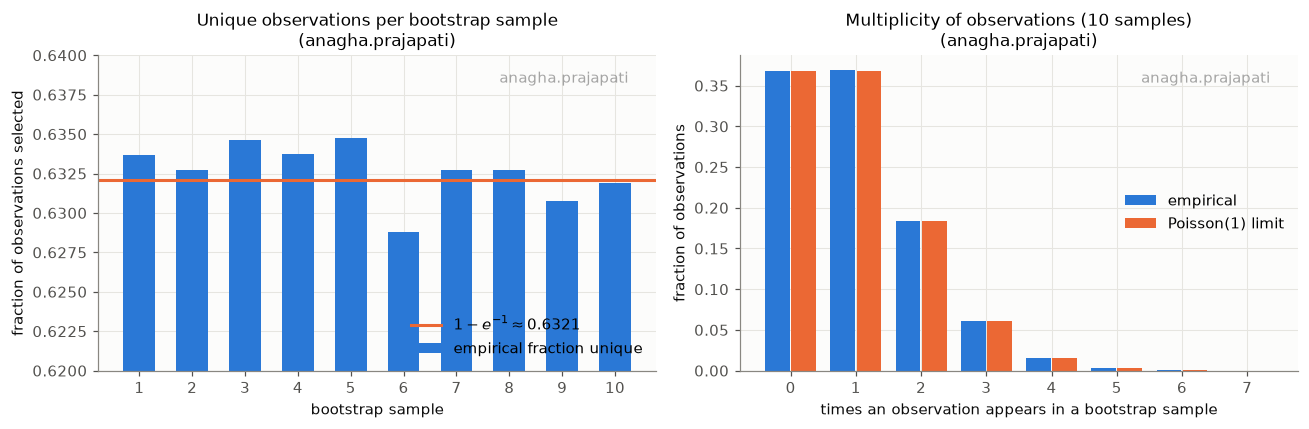

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.bar(boot_table.index, boot_table["fraction unique"], color=BLUE, width=0.6, label="empirical fraction unique")
ax.axhline(theory_limit, color=ORANGE, lw=2, label=r"$1-e^{-1} \approx 0.6321$")
ax.set_ylim(0.62, 0.64)
ax.set_xticks(boot_table.index)
ax.set_xlabel("bootstrap sample")
ax.set_ylabel("fraction of observations selected")
ax.legend(loc="lower right")
titled(ax, "Unique observations per bootstrap sample")

ax = axes[1]
all_counts = np.concatenate(multiplicities)
kmax = 7
emp = np.array([(all_counts == k).mean() for k in range(kmax + 1)])
poisson = np.array([math.exp(-1) / math.factorial(k) for k in range(kmax + 1)])
ax.bar(np.arange(kmax + 1) - 0.2, emp, width=0.38, color=BLUE, label="empirical")
ax.bar(np.arange(kmax + 1) + 0.2, poisson, width=0.38, color=ORANGE, label="Poisson(1) limit")
ax.set_xlabel("times an observation appears in a bootstrap sample")
ax.set_ylabel("fraction of observations")
ax.legend(loc="center right")
titled(ax, "Multiplicity of observations (10 samples)")
finish(fig, "1_3_1_bootstrap")

**Why ≈63.2% of the observations appear in a bootstrap sample.**
A single draw picks a particular observation $i$ with probability $1/N$, so it *misses* it with probability $1-1/N$. The $N$ draws are independent, so

$$P(i \text{ never selected}) = \left(1-\frac1N\right)^N \xrightarrow{N\to\infty} e^{-1} \approx 0.368,
\qquad P(i \text{ selected at least once}) = 1-\left(1-\frac1N\right)^N \to 1-e^{-1}\approx 0.632.$$

(We used $\lim_{N\to\infty}(1+x/N)^N = e^x$ with $x=-1$.) By linearity of expectation, the expected number of distinct observations is $N(1-(1-1/N)^N)$. For our $N = 26{,}049$ this is $0.63213 N$, essentially the limit.

**Empirical vs theoretical.** All 10 bootstrap samples contain between 62.9% and 63.5% unique observations. Their mean, 0.6326, differs from $1-e^{-1} = 0.6321$ by only 0.0005. The sample-to-sample standard deviation (0.0018) matches the theoretical value $\sqrt{(e^{-1}-2e^{-2})/N}\approx 0.0019$. This is smaller than a naive binomial estimate, because the events "observation $i$ is never drawn" are negatively correlated across observations. The right plot confirms the full picture: the number of times an observation is drawn is Binomial$(N, 1/N)\approx$ Poisson(1). About 36.8% of observations appear 0 times, 36.8% once, 18.4% twice, and so on. The ≈36.8% never drawn are the **out-of-bag (OOB)** observations of that sample; they act as a free validation set for the tree trained on it (Section 1.5).

## 1.3.2 Bagged Trees

**Bagging** trains $B$ full CART trees, each on its own bootstrap sample and searching **all features at every split**, and predicts by **majority vote**. Exact ties (possible for even $B$) go to the majority class `<=50K`.

Implementation notes:
* `_fit_bootstrap_tree` (the routine that trains a single ensemble member) draws the bootstrap sample, fits a `DecisionTree` on it, and records the out-of-bag rows. The same routine is reused by the Random Forest in 1.4.
* Tree $b$ gets its own random stream, `SeedSequence(SEED).spawn(B)[b]`. Results are therefore reproducible and **independent of the number of worker processes**. Ensembles with the same seed also share their first trees' bootstrap samples (common random numbers), which makes comparisons between settings fairer.
* **Training time** is measured with the trees fitted one after another on a single core (`n_jobs=1`). The table also reports the machine-independent split-search work.

In [24]:
def majority_vote(votes_for_positive, n_voters):
    """Majority vote for labels {0,1}: predict 1 iff strictly more than half of the voters say 1 (tie -> 0)."""
    return (2 * np.asarray(votes_for_positive) > np.asarray(n_voters)).astype(np.int64)


def _fit_bootstrap_tree(X, y, tree_params, seed_seq):
    """Train one ensemble member: bootstrap sample -> DecisionTree -> out-of-bag indices."""
    t0 = time.perf_counter()
    rng = np.random.default_rng(seed_seq)
    n = len(y)
    boot = bootstrap_sample(n, rng)
    tree = DecisionTree(**tree_params, random_state=rng, keep_nodes=False).fit(X[boot], y[boot])
    in_bag = np.zeros(n, dtype=bool)
    in_bag[boot] = True
    oob_idx = np.flatnonzero(~in_bag).astype(np.int32)       # observations NOT selected for this tree
    return tree, oob_idx, time.perf_counter() - t0


def fit_bootstrap_trees(X, y, tree_params, n_trees, random_state, n_jobs):
    seeds = np.random.SeedSequence(random_state).spawn(n_trees)       # one independent stream per tree
    if n_jobs == 1 or n_trees == 1:
        return [_fit_bootstrap_tree(X, y, tree_params, s) for s in seeds]
    return Parallel(n_jobs=min(n_jobs, n_trees))(delayed(_fit_bootstrap_tree)(X, y, tree_params, s) for s in seeds)


class BaggedTrees:
    """Bagging: bootstrap samples + full CART trees using ALL features at every split + majority vote."""

    def __init__(self, n_estimators=10, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 criterion="gini", random_state=None, n_jobs=1):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.min_samples_split, self.min_samples_leaf = min_samples_split, min_samples_leaf
        self.criterion, self.random_state, self.n_jobs = criterion, random_state, n_jobs

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=np.float64), np.asarray(y, dtype=np.int64)
        params = dict(max_depth=self.max_depth, min_samples_split=self.min_samples_split,
                      min_samples_leaf=self.min_samples_leaf, criterion=self.criterion, max_features=None)
        t0 = time.perf_counter()
        results = fit_bootstrap_trees(X, y, params, self.n_estimators, self.random_state, self.n_jobs)
        self.fit_time_ = time.perf_counter() - t0
        self.trees_ = [r[0] for r in results]
        self.oob_indices_ = [r[1] for r in results]
        self.tree_fit_times_ = np.array([r[2] for r in results])
        return self

    def predict(self, X):
        votes = np.sum([t.predict(X) for t in self.trees_], axis=0)
        return majority_vote(votes, len(self.trees_))

    def work(self):
        """Total number of feature values examined by all trees, in millions (machine-independent cost)."""
        return sum(t.n_values_examined_ for t in self.trees_) / 1e6

,train acc,val acc,"training time (s, 1 core)",time / tree (s),work (M values examined),mean leaves / tree,val error
B,,,,,,,
1,0.9326,0.8131,2.48,2.48,29,2539,0.1869
10,0.9878,0.8503,23.03,2.30,290,2466,0.1497
25,0.9981,0.8497,51.84,2.07,718,2485,0.1503
50,0.9994,0.8477,108.61,2.17,1414,2492,0.1523
100,0.9999,0.8515,228.39,2.28,2830,2488,0.1485


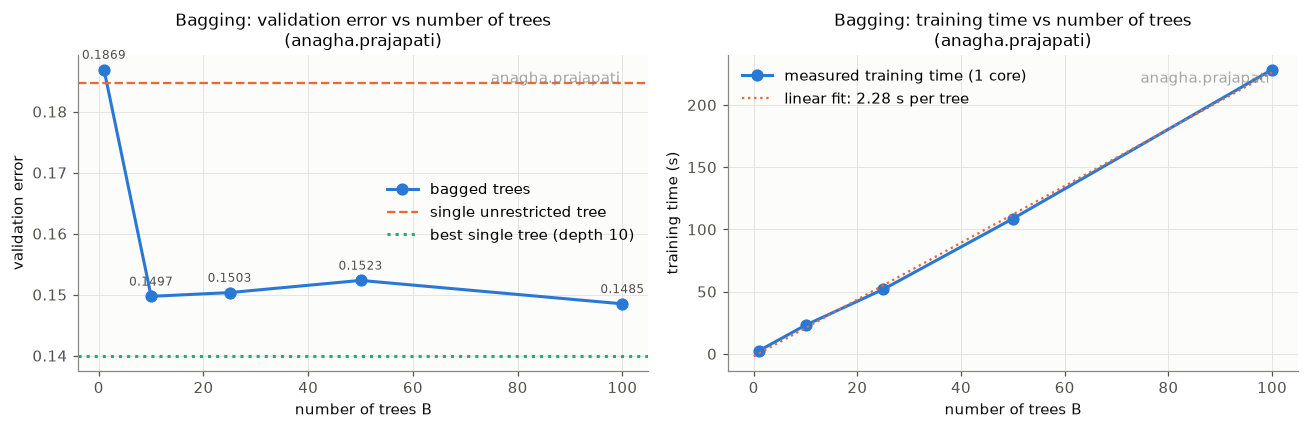

In [25]:
bag_rows, bag_models = [], {}
for B in [1, 10, 25, 50, 100]:
    bag = BaggedTrees(n_estimators=B, random_state=SEED, n_jobs=1).fit(X_train, y_train)
    bag_models[B] = bag
    bag_rows.append({"B": B, "train acc": accuracy_score(y_train, bag.predict(X_train)),
                     "val acc": accuracy_score(y_val, bag.predict(X_val)),
                     "training time (s, 1 core)": bag.fit_time_, "time / tree (s)": bag.fit_time_ / B,
                     "work (M values examined)": bag.work(),
                     "mean leaves / tree": np.mean([t.n_leaves_ for t in bag.trees_])})
bag_table = pd.DataFrame(bag_rows).set_index("B")
del bag_models  # free memory (only the metrics are needed later)
bag_table["val error"] = 1 - bag_table["val acc"]
display(fmt(bag_table).format("{:.4f}", subset=["train acc", "val acc", "val error"])
        .format("{:.2f}", subset=["training time (s, 1 core)", "time / tree (s)"])
        .format("{:.0f}", subset=["mean leaves / tree", "work (M values examined)"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(bag_table.index, bag_table["val error"], "o-", color=BLUE, label="bagged trees")
ax.axhline(1 - depth_table.loc["unrestricted", "val acc"], color=ORANGE, ls="--", lw=1.5, label="single unrestricted tree")
ax.axhline(1 - best_row["val acc"], color=AQUA, ls=":", lw=2, label=f"best single tree (depth {BEST_TREE_DEPTH})")
for B, e in bag_table["val error"].items():
    ax.annotate(f"{e:.4f}", (B, e), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=INK2)
ax.set_xlabel("number of trees B")
ax.set_ylabel("validation error")
ax.legend(loc="center right")
titled(ax, "Bagging: validation error vs number of trees")
ax = axes[1]
bag_slope, bag_icpt = np.polyfit(bag_table.index.values, bag_table["training time (s, 1 core)"].values, 1)
ax.plot(bag_table.index, bag_table["training time (s, 1 core)"], "o-", color=BLUE, label="measured training time (1 core)")
ax.plot([0, 100], [bag_icpt, bag_icpt + 100 * bag_slope], ls=":", color=ORANGE, lw=1.5, label=f"linear fit: {bag_slope:.2f} s per tree")
ax.set_xlabel("number of trees B")
ax.set_ylabel("training time (s)")
ax.legend(loc="upper left")
titled(ax, "Bagging: training time vs number of trees")
finish(fig, "1_3_2_bagging")

**Discussion: bagging**

* $B = 1$ is a single unrestricted tree trained on one bootstrap sample. It sees only ≈63% of the distinct observations, so it is slightly worse (81.3%) than the unrestricted tree trained on all the data (81.5%).
* Averaging trees cuts the validation error sharply, from 18.7% at $B=1$ to 15.0% at $B=10$. After that the error is flat: it moves between 14.9% and 15.2% for $B$ = 10 to 100, which is within noise. Bagging **reduces variance**: every unrestricted tree overfits its own bootstrap sample in a different way, and voting averages much of that noise away.
* Bagging does **not** reduce bias, and it cannot remove the variance that all trees share. Every tree searches all features, so the trees keep choosing the same dominant splits near the root and stay **strongly correlated** (mean pairwise correlation 0.53, measured in 1.4.1). This is why 100 bagged unrestricted trees (85.2%) are far better than one unrestricted tree (81.5%) but still do not beat the single depth-10 tree (86.0%). Random Forests (1.4) attack exactly this correlation.
* **Cost.** Both the work and the training time grow **linearly in B**: the work is ≈28–29 million values per tree for every $B$, and the measured time per tree is roughly constant (≈2–2.5 s on this machine).

---
# 1.4 Random Forest from Scratch

> **Order of sub-sections:** the implementation (1.4.2) is presented first, because the experiment of 1.4.1 needs it. The node-level random feature selection itself lives in `DecisionTree._candidate_features` (1.2.2) and is demonstrated again below.

## 1.4.2 Implementation

`RandomForest.fit` trains `n_estimators` trees. For each tree it:
1. **trains it on a bootstrap sample**: `_fit_bootstrap_tree` draws $N$ indices with replacement using `bootstrap_sample`;
2. **keeps track of the observations that were not selected**: the out-of-bag indices are stored per tree in `oob_indices_`;
3. **randomly selects features at every split**: the tree is a `DecisionTree(max_features=m)`, which draws a *new* random subset of $m$ features at every node;
4. **stores the tree in the forest**: `trees_` is the list of fitted trees.

`predict` uses **majority voting** over all trees (`majority_vote`, ties → `<=50K`). `fit` also computes the **out-of-bag prediction** of every training observation, using only the trees for which it was OOB (details in 1.5). `feature_importances_` aggregates the impurity decreases of all splits of all trees (1.7.1).

In [26]:
class RandomForest:
    """Random Forest classifier (labels {0,1}) built from our DecisionTree."""

    def __init__(self, n_estimators=100, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                 max_features="sqrt", criterion="gini", random_state=None, n_jobs=1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.criterion = criterion
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=np.float64), np.asarray(y, dtype=np.int64)
        self.n_features_ = X.shape[1]
        self.max_features_ = resolve_max_features(self.max_features, self.n_features_)
        tree_params = dict(max_depth=self.max_depth, min_samples_split=self.min_samples_split,
                           min_samples_leaf=self.min_samples_leaf, criterion=self.criterion,
                           max_features=self.max_features_)
        t0 = time.perf_counter()
        results = fit_bootstrap_trees(X, y, tree_params, self.n_estimators, self.random_state, self.n_jobs)
        self.fit_time_ = time.perf_counter() - t0                       # wall-clock training time
        self.trees_ = [r[0] for r in results]                            # (4) trees stored in the forest
        self.oob_indices_ = [r[1] for r in results]                      # (2) not-selected observations per tree
        self.tree_fit_times_ = np.array([r[2] for r in results])
        self._compute_oob(X, y)
        return self

    # ---------------------------------------------------------------- prediction
    def tree_predictions(self, X):
        """(B, n) matrix of the individual tree predictions."""
        return np.vstack([t.predict(X) for t in self.trees_])

    def predict_votes(self, X):
        return self.tree_predictions(X).sum(axis=0)

    def predict(self, X):
        return majority_vote(self.predict_votes(X), len(self.trees_))

    # ---------------------------------------------------------------- out-of-bag
    def _compute_oob(self, X, y):
        n = len(y)
        votes = np.zeros(n, dtype=np.int64)    # OOB votes for >50K
        counts = np.zeros(n, dtype=np.int64)   # number of trees for which the observation is OOB
        for tree, oob in zip(self.trees_, self.oob_indices_):
            votes[oob] += tree.predict(X[oob])
            counts[oob] += 1
        self.oob_votes_, self.oob_counts_ = votes, counts
        has_oob = counts > 0
        # observations that were in-bag for EVERY tree get no OOB prediction: marked -1 and excluded
        self.oob_prediction_ = np.full(n, -1, dtype=np.int64)
        self.oob_prediction_[has_oob] = majority_vote(votes[has_oob], counts[has_oob])
        self.oob_coverage_ = float(has_oob.mean())
        self.n_without_oob_ = int((~has_oob).sum())
        self.oob_score_ = accuracy_score(y[has_oob], self.oob_prediction_[has_oob]) if has_oob.any() else float("nan")

    # ---------------------------------------------------------------- model summaries
    @property
    def feature_importances_(self):
        total = np.sum([t.impurity_decrease_ for t in self.trees_], axis=0)
        return total / total.sum()

    def work(self):
        """Total number of feature values examined by all trees, in millions (machine-independent cost)."""
        return sum(t.n_values_examined_ for t in self.trees_) / 1e6

    def complexity(self):
        leaves = np.array([t.n_leaves_ for t in self.trees_])
        depths = np.array([t.depth_ for t in self.trees_])
        return {"trees": len(self.trees_), "total leaves": int(leaves.sum()), "mean leaves/tree": float(leaves.mean()),
                "total nodes": int(sum(t.n_nodes_ for t in self.trees_)), "mean depth": float(depths.mean()),
                "max depth": int(depths.max())}


def tree_diversity(forest, X, y):
    """Mean accuracy of the individual trees (strength) and mean pairwise correlation of their predictions."""
    P = forest.tree_predictions(X).astype(np.float64)
    strength = float(np.mean([(row == y).mean() for row in P]))
    if len(P) < 2:
        return strength, float("nan")
    with np.errstate(divide="ignore", invalid="ignore"):
        C = pearson_corr_matrix(P.T)
    return strength, float(np.nanmean(C[~np.eye(len(P), dtype=bool)]))

In [27]:
# ---- verification of the four requirements and of majority voting on a small forest
demo_rf = RandomForest(n_estimators=6, max_features="sqrt", random_state=SEED, n_jobs=N_JOBS).fit(X_train, y_train)
print(f"p = {p}, m = max_features_ = {demo_rf.max_features_} (= round(sqrt(p)))")
print("(1)+(2) fraction of training rows OOB for each tree:",
      [round(len(o) / len(y_train), 4) for o in demo_rf.oob_indices_], "(theory 0.3679)")
print("(4) trees stored in the forest:", len(demo_rf.trees_), "| leaves per tree:", [t.n_leaves_ for t in demo_rf.trees_])

# majority voting: manual vote == predict()
P = demo_rf.tree_predictions(X_val)
manual = (P.sum(0) * 2 > len(P)).astype(int)
print("majority vote recomputed by hand == predict():", bool(np.all(manual == demo_rf.predict(X_val))))


# (3) feature subsets are drawn independently at every node: record the candidate sets of one tree
class RecordingTree(DecisionTree):
    def _candidate_features(self, idx, active):
        feats, values, active = super()._candidate_features(idx, active)
        self.log.append((idx.size, sorted(int(f) for f in feats)))
        return feats, values, active


rec = RecordingTree(max_features=resolve_max_features("sqrt", p), random_state=np.random.default_rng(SEED))
rec.log = []
rec.fit(X_train, y_train)
print(f"\n(3) candidate features drawn at the first 6 nodes of one tree (m = {rec.max_features_}):")
for n_node, feats in rec.log[:6]:
    print(f"   node with {n_node:5d} samples -> candidate features {feats}")
distinct = len({tuple(f) for _, f in rec.log})
print(f"   {distinct} distinct candidate subsets over {len(rec.log)} split searches -> a new subset at every node")

# bagging is the special case m = p: same seed -> identical predictions to BaggedTrees
rf_all = RandomForest(n_estimators=6, max_features=None, random_state=SEED, n_jobs=N_JOBS).fit(X_train, y_train)
bag_6 = BaggedTrees(n_estimators=6, random_state=SEED, n_jobs=N_JOBS).fit(X_train, y_train)
print("\nRandomForest(max_features=p) == BaggedTrees (same seed):", bool(np.all(rf_all.predict(X_val) == bag_6.predict(X_val))))

p = 88, m = max_features_ = 9 (= round(sqrt(p)))
(1)+(2) fraction of training rows OOB for each tree: [0.3653, 0.3656, 0.3674, 0.3701, 0.3647, 0.3699] (theory 0.3679)
(4) trees stored in the forest: 6 | leaves per tree: [2868, 2795, 2804, 2723, 2733, 2835]
majority vote recomputed by hand == predict(): True



(3) candidate features drawn at the first 6 nodes of one tree (m = 9):
   node with 26049 samples -> candidate features [3, 5, 12, 16, 25, 29, 30, 57, 62]
   node with 14017 samples -> candidate features [7, 13, 19, 24, 30, 33, 42, 47, 66]
   node with 12710 samples -> candidate features [4, 9, 20, 50, 57, 59, 60, 69, 80]
   node with 12680 samples -> candidate features [1, 8, 33, 46, 48, 52, 62, 74, 81]
   node with  6143 samples -> candidate features [2, 19, 26, 32, 48, 55, 56, 58, 66]
   node with  5050 samples -> candidate features [0, 21, 22, 31, 44, 65, 79, 83, 86]
   3245 distinct candidate subsets over 4224 split searches -> a new subset at every node



RandomForest(max_features=p) == BaggedTrees (same seed): True


## 1.4.1 Random Feature Selection

At every internal node only $m$ randomly chosen features are considered, drawn anew at each node (see `DecisionTree._candidate_features` and the demonstration above). We compare

$$m \in \{1,\ \sqrt p,\ p/2,\ p\} = \{1,\ 9,\ 44,\ 88\} \qquad (p = 88,\ \sqrt{88}\approx 9.38 \to 9,\ 88/2 = 44).$$

For a fair comparison, everything else is fixed: $B = 100$ trees, `max_depth = None`, `min_samples_leaf = 1`, `min_samples_split = 2`, Gini, and the same seed. With the same seed, tree $b$ uses the **same bootstrap sample** for every $m$, so only the feature sampling differs. $m = p$ is exactly bagging.

Besides the required metrics we report two classic quantities from Breiman's analysis of forests:
* the **strength**: the mean validation accuracy of an individual tree;
* the **correlation**: the mean pairwise correlation between the trees' validation predictions.

In [28]:
B_FIXED = 100
m_values = [1, resolve_max_features("sqrt", p), resolve_max_features("half", p), p]
m_rows, m_forests = [], {}
for m in m_values:
    rf = RandomForest(n_estimators=B_FIXED, max_depth=None, min_samples_split=2, min_samples_leaf=1,
                      max_features=m, random_state=SEED, n_jobs=1).fit(X_train, y_train)
    strength, rho = tree_diversity(rf, X_val, y_val)
    cx = rf.complexity()
    m_rows.append({"m": m, "train acc": accuracy_score(y_train, rf.predict(X_train)),
                   "val acc": accuracy_score(y_val, rf.predict(X_val)), "OOB acc": rf.oob_score_,
                   "training time (s, 1 core)": rf.fit_time_, "work (M values examined)": rf.work(),
                   "tree strength (val)": strength, "tree correlation (val)": rho,
                   "mean leaves/tree": cx["mean leaves/tree"], "mean depth": cx["mean depth"]})
    m_forests[m] = rf
m_table = pd.DataFrame(m_rows).set_index("m")
display(fmt(m_table).format("{:.4f}", subset=["train acc", "val acc", "OOB acc", "tree strength (val)", "tree correlation (val)"])
        .format("{:.1f}", subset=["training time (s, 1 core)", "mean leaves/tree", "mean depth"])
        .format("{:.0f}", subset=["work (M values examined)"]))

,train acc,val acc,OOB acc,"training time (s, 1 core)",work (M values examined),tree strength (val),tree correlation (val),mean leaves/tree,mean depth
m,,,,,,,,,
1,0.9999,0.8506,0.8461,110.9,729,0.7970,0.4567,5035.7,66.2
9,0.9999,0.8587,0.8572,111.8,1270,0.8106,0.4996,2791.6,45.7
44,0.9999,0.8570,0.8537,166.7,2265,0.8140,0.5248,2501.9,42.2
88,0.9999,0.8515,0.8530,212.9,2830,0.8140,0.5299,2487.9,42.9


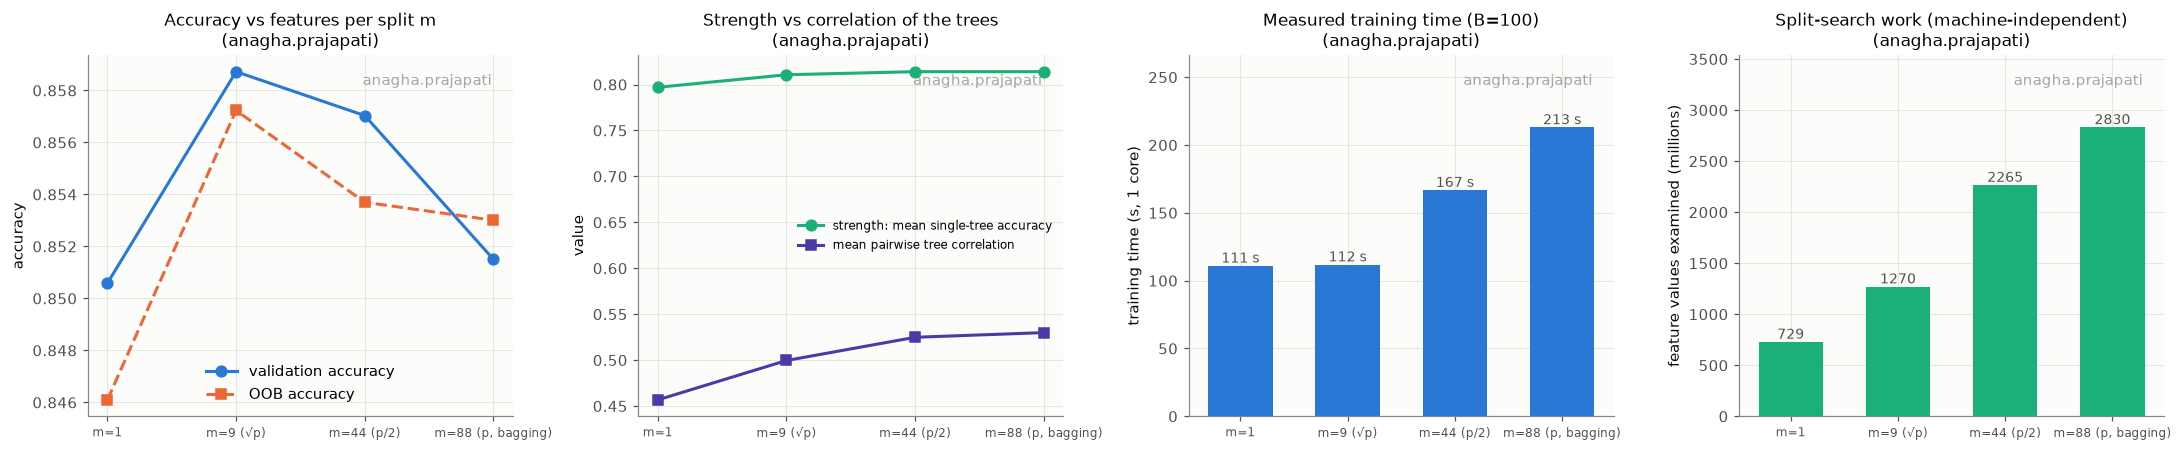

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
xs = np.arange(len(m_values))
xl = [f"m={m}" + (" (√p)" if m == m_values[1] else " (p/2)" if m == m_values[2] else " (p, bagging)" if m == p else "") for m in m_values]
ax = axes[0]
ax.plot(xs, m_table["val acc"], "o-", color=BLUE, label="validation accuracy")
ax.plot(xs, m_table["OOB acc"], "s--", color=ORANGE, label="OOB accuracy")
ax.set_xticks(xs, xl, fontsize=8)
ax.set_ylabel("accuracy")
ax.legend(loc="lower center")
titled(ax, "Accuracy vs features per split m")
ax = axes[1]
ax.plot(xs, m_table["tree strength (val)"], "o-", color=AQUA, label="strength: mean single-tree accuracy")
ax.plot(xs, m_table["tree correlation (val)"], "s-", color=VIOLET, label="mean pairwise tree correlation")
ax.set_xticks(xs, xl, fontsize=8)
ax.set_ylabel("value")
ax.legend(loc="center right", fontsize=8)
titled(ax, "Strength vs correlation of the trees")
ax = axes[2]
bars = ax.bar(xs, m_table["training time (s, 1 core)"], width=0.6, color=BLUE)
for b_, v in zip(bars, m_table["training time (s, 1 core)"]):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:.0f} s", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(xs, xl, fontsize=8)
ax.set_ylabel("training time (s, 1 core)")
ax.set_ylim(0, m_table["training time (s, 1 core)"].max() * 1.25)
titled(ax, f"Measured training time (B={B_FIXED})")
ax = axes[3]
bars = ax.bar(xs, m_table["work (M values examined)"], width=0.6, color=AQUA)
for b_, v in zip(bars, m_table["work (M values examined)"]):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(xs, xl, fontsize=8)
ax.set_ylabel("feature values examined (millions)")
ax.set_ylim(0, m_table["work (M values examined)"].max() * 1.25)
titled(ax, "Split-search work (machine-independent)")
finish(fig, "1_4_1_max_features")

**Discussion: number of candidate features m**

* **Training accuracy is 99.99% for every m.** The trees are unrestricted, so training accuracy cannot discriminate between the settings; validation and OOB accuracy must be used.
* **m = p = 88 (bagging)** has the **strongest individual trees** (mean single-tree validation accuracy 0.814) but also the **most correlated** ones (0.530). Every tree sees all features and keeps choosing the same dominant splits, so the ensemble averages away less variance: 85.2% validation, 85.3% OOB.
* **m = √p = 9 is the best setting**: 85.9% validation and 85.7% OOB. Restricting the candidates forces the trees to use different features and different split orders. The correlation falls to 0.500 while the strength falls only slightly, to 0.811. m = p/2 = 44 lies in between (85.7% validation, 85.4% OOB; correlation 0.525).
* **m = 1 goes too far.** The split feature is essentially random, so each tree is weaker (strength 0.797) and much larger (5,036 leaves and 66 levels on average, against 2,792 leaves for m = 9). It has the lowest correlation (0.457), but that does not make up for the lost strength: 85.1% validation, 84.6% OOB.
* This is the trade-off in Breiman's bound, generalisation error ≲ $\bar\rho\,(1-s^2)/s^2$: lowering m reduces the correlation $\bar\rho$ but also the strength $s$. The best m balances the two.
* **How strong is the evidence?** The differences between m = 9, 44 and 88 are 0.2–0.7 percentage points, comparable to the validation standard error (0.43 points). Validation and OOB accuracy are computed on different data, however, and they give the same ordering (9 > 44 > 88 > 1), which makes the conclusion more credible than either estimate alone.
* **Cost.** The split-search work grows with m: 729, 1,270, 2,265 and 2,830 million values for m = 1, 9, 44, 88. It grows much more slowly than m itself, for two reasons. Deep nodes contain many one-hot columns that are constant, so the search has to draw (and examine) extra features to find m usable ones. And for m = 1 the trees are almost twice as large. The measured training times follow the same pattern (m = 1 and m = 9 take about the same time; m = 44 and m = 88 take clearly longer).
* **Choice.** m = √p = 9 is the most accurate setting and one of the cheapest. **We use m = 9 as the default from here on.**

## 1.4.3 Number of Trees Experiment

$B \in \{1, 10, 50, 100, 250\}$ with $m = \sqrt p = 9$, `max_depth = None`, `min_samples_leaf = 1`, `min_samples_split = 2`, and the same seed. Every forest is trained from scratch.

To measure **how the training cost scales with B** without distortion from parallel scheduling, these forests are trained **sequentially on a single core** (`n_jobs=1`). The reported training time is therefore the true single-core cost.

In [30]:
B_values = [1, 10, 50, 100, 250]
M_DEFAULT = resolve_max_features("sqrt", p)
B_rows, B_forests = [], {}
for B in B_values:
    rf = RandomForest(n_estimators=B, max_features=M_DEFAULT, random_state=SEED, n_jobs=1).fit(X_train, y_train)
    B_forests[B] = rf
    B_rows.append({"B": B, "train acc": accuracy_score(y_train, rf.predict(X_train)),
                   "val acc": accuracy_score(y_val, rf.predict(X_val)), "OOB acc": rf.oob_score_,
                   "OOB coverage": rf.oob_coverage_,
                   "training time (s, 1 core)": rf.fit_time_, "time / tree (s)": rf.fit_time_ / B,
                   "work (M values examined)": rf.work()})
B_table = pd.DataFrame(B_rows).set_index("B")
B_table["val error"] = 1 - B_table["val acc"]
display(fmt(B_table).format("{:.4f}", subset=["train acc", "val acc", "OOB acc", "OOB coverage", "val error"])
        .format("{:.2f}", subset=["training time (s, 1 core)", "time / tree (s)"])
        .format("{:.0f}", subset=["work (M values examined)"]))
print("Forest with B=100 identical to the m=sqrt(p) forest of 1.4.1 (same seed):",
      bool(np.all(B_forests[100].predict(X_val) == m_forests[M_DEFAULT].predict(X_val))))

# staged validation error of the 250-tree forest: the first b trees of it form a forest with b trees
P250_val = B_forests[250].tree_predictions(X_val)
staged_val_err = np.array([1 - accuracy_score(y_val, majority_vote(P250_val[:b].sum(0), b)) for b in range(1, 251)])

,train acc,val acc,OOB acc,OOB coverage,"training time (s, 1 core)",time / tree (s),work (M values examined),val error
B,,,,,,,,
1,0.9322,0.8090,0.8144,0.3653,1.07,1.07,14,0.1910
10,0.9876,0.8526,0.8372,0.9900,10.88,1.09,129,0.1474
50,0.9995,0.8580,0.8542,1.0000,58.83,1.18,635,0.1420
100,0.9999,0.8587,0.8572,1.0000,112.75,1.13,1270,0.1413
250,1.0000,0.8603,0.8591,1.0000,295.37,1.18,3172,0.1397


Forest with B=100 identical to the m=sqrt(p) forest of 1.4.1 (same seed): True


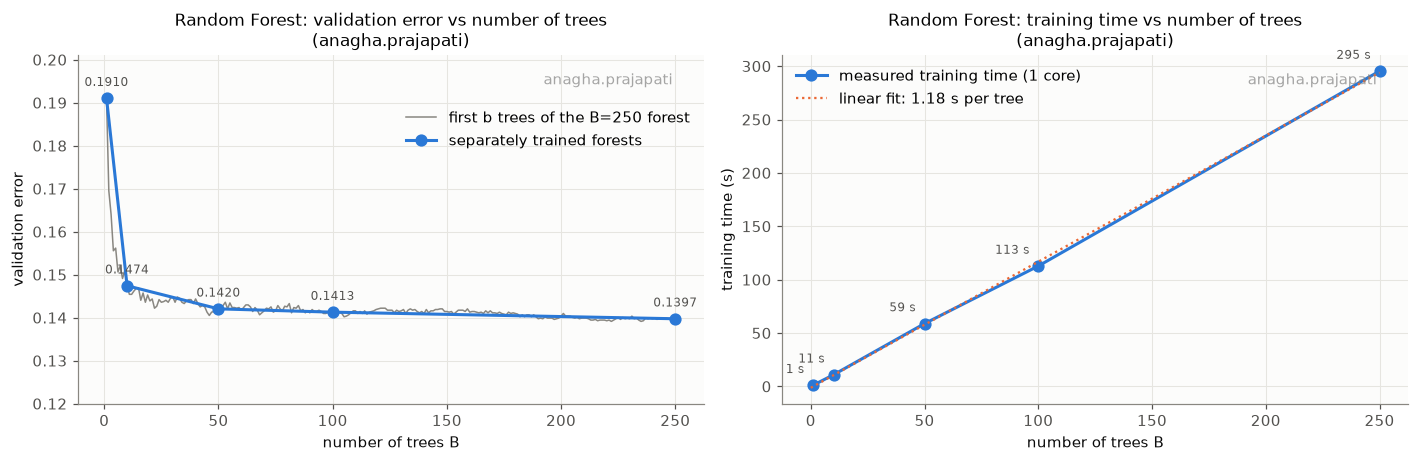

In [31]:
slope, intercept = np.polyfit(B_table.index.values, B_table["training time (s, 1 core)"].values, 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(np.arange(1, 251), staged_val_err, color=MUTED, lw=1, label="first b trees of the B=250 forest")
ax.plot(B_table.index, B_table["val error"], "o-", color=BLUE, label="separately trained forests")
for B, e in B_table["val error"].items():
    ax.annotate(f"{e:.4f}", (B, e), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, color=INK2)
ax.set_xlabel("number of trees B")
ax.set_ylabel("validation error")
ax.set_ylim(0.12, max(0.2, B_table["val error"].max() + 0.01))
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.88))
titled(ax, "Random Forest: validation error vs number of trees")
ax = axes[1]
ax.plot(B_table.index, B_table["training time (s, 1 core)"], "o-", color=BLUE, label="measured training time (1 core)")
bb = np.linspace(0, 250, 50)
ax.plot(bb, slope * bb + intercept, ls=":", color=ORANGE, lw=1.5, label=f"linear fit: {slope:.2f} s per tree")
for B, t in B_table["training time (s, 1 core)"].items():
    ax.annotate(f"{t:.0f} s", (B, t), textcoords="offset points", xytext=(-6, 8), ha="right", fontsize=8, color=INK2)
ax.set_xlabel("number of trees B")
ax.set_ylabel("training time (s)")
ax.legend(loc="upper left")
titled(ax, "Random Forest: training time vs number of trees")
finish(fig, "1_4_3_number_of_trees")

**Discussion: number of trees**

1. **Effect on performance.** A single randomised tree ($B=1$) is weak: 80.9% validation accuracy. That is worse than one ordinary unrestricted tree (81.5%), because it sees only a bootstrap sample and only 9 random features per split. Validation error then falls steeply, from 19.1% to 14.7% at $B=10$, and flattens: 14.2% at $B=50$, 14.1% at $B=100$ and 14.0% at $B=250$. The thin grey curve (sub-forests of the 250-tree forest) shows the classic picture: the error converges to a plateau and **does not rise again with more trees**. Adding trees only reduces the variance of the vote towards its limit $\rho\sigma^2$; it does not overfit. Training accuracy is ≈100% from $B = 50$ on, because unrestricted trees fit their bootstrap samples almost perfectly.
2. **Computational cost.** Trees are trained independently, so the cost is **linear in B**. The machine-independent work is exactly proportional: 12.7 million values per tree for every $B$ (14, 129, 635, 1,270, 3,172 million). The measured single-core time agrees: about 1.1–1.2 s per tree at every $B$, and 295 s for 250 trees. Memory and prediction time are linear in $B$ as well.
3. **Trade-off.** Most of the gain is reached by **$B \approx 50$–$100$**. Going from 100 to 250 trees costs 2.5× more training and prediction time and changes validation accuracy by 0.16 percentage points, well inside the standard error of the validation estimate (≈0.43 points). We therefore take **$B = 100$** as a reasonable default; $B = 50$ is acceptable when compute is tight. $B = 250$ is checked again during hyperparameter selection (1.6.3).

## 1.4.4 Single Tree versus Random Forest

We compare the best single tree (selected on validation in 1.2.3) with the best Random Forest found so far (the highest validation accuracy among the forests of 1.4.1 and 1.4.3). The tuned forest of 1.6.3 is compared again at the end of Section 1.6.

In [32]:
candidates = {**{f"RF m={m}, B={B_FIXED}": f for m, f in m_forests.items()},
              **{f"RF m={M_DEFAULT}, B={B}": f for B, f in B_forests.items()}}
best_rf_name = max(candidates, key=lambda k: accuracy_score(y_val, candidates[k].predict(X_val)))
best_rf_so_far = candidates[best_rf_name]


def model_summary(name, model, fit_time):
    if isinstance(model, DecisionTree):
        cx = {"trees": 1, "total leaves": model.n_leaves_, "total nodes": model.n_nodes_,
              "mean depth": model.depth_, "max depth": model.depth_}
    else:
        cx = model.complexity()
    return {"model": name, "train acc": accuracy_score(y_train, model.predict(X_train)),
            "val acc": accuracy_score(y_val, model.predict(X_val)),
            "train time (s, 1 core)": fit_time,
            "work (M values examined)": model.n_values_examined_ / 1e6 if isinstance(model, DecisionTree) else model.work(),
            "trees": cx["trees"], "total leaves": cx["total leaves"], "total nodes": cx["total nodes"],
            "mean tree depth": cx["mean depth"], "max tree depth": cx["max depth"]}


cmp_table = pd.DataFrame([
    model_summary(f"best single tree (max_depth={BEST_TREE_DEPTH})", best_tree, best_tree_time),
    model_summary("unrestricted single tree", depth_trees[None], depth_table.loc["unrestricted", "train time (s)"]),
    model_summary(f"best Random Forest so far ({best_rf_name})", best_rf_so_far, best_rf_so_far.fit_time_),
]).set_index("model")
display(fmt(cmp_table).format("{:.4f}", subset=["train acc", "val acc"])
        .format("{:.2f}", subset=["train time (s, 1 core)", "mean tree depth"])
        .format("{:.1f}", subset=["work (M values examined)"]))

,train acc,val acc,"train time (s, 1 core)",work (M values examined),trees,total leaves,total nodes,mean tree depth,max tree depth
model,,,,,,,,,
best single tree (max_depth=10),0.8712,0.8601,0.99,20.1,1,255,509,10.00,10
unrestricted single tree,1.0000,0.8153,2.36,30.7,1,3813,7625,49.00,49
"best Random Forest so far (RF m=9, B=250)",1.0000,0.8603,295.37,3172.1,250,700308,1400366,45.75,65


**Discussion: single tree vs Random Forest**

**What the numbers say.**
* The forest is built from *unrestricted* trees. One such tree reaches only 81.5% on validation. Averaging 250 randomised versions of it gives 86.0%, a gain of 4.5 percentage points from ensembling alone.
* Against the **best** single tree (depth 10, selected on validation among 21 depths), this default forest is only **level**: 86.03% vs 86.01%. A carefully pruned tree is a strong baseline on this data set. Two points qualify the tie. The single tree's score is the maximum over 21 candidates evaluated on the same validation set, so it is slightly optimistic. And the forest here is untuned: after tuning (1.6.3) it reaches 86.7% on validation, and on the untouched test set the tuned forest beats the tree by 0.65 points (1.8).
* **Complexity and cost.** The tree has 255 leaves and trains in about 1 s. The forest has 700,308 leaves (2,750 times more), needs about 160 times more split-search work (3,172 vs 20 million values) and correspondingly more time. It is also much less interpretable than one readable tree; Section 1.7 restores some interpretability with feature importances.

**Why an ensemble of randomised trees can outperform an individual tree.**
* A single tree must choose between two evils. Grown deep, it has low bias but very high variance (it memorises noise: 100% train, 81.5% validation). Pruned, it gives up some signal to gain stability (higher bias).
* A forest keeps **deep, low-bias trees** and removes their variance by averaging. For $B$ identically distributed trees with variance $\sigma^2$ and pairwise correlation $\rho$, the variance of their average is
  $$\operatorname{Var}\Big(\tfrac1B\textstyle\sum_b T_b\Big) = \rho\,\sigma^2 + \tfrac{1-\rho}{B}\,\sigma^2 .$$
  A larger $B$ removes the second term. Bootstrap sampling and, above all, **per-node random feature selection** lower $\rho$ and so shrink the first term, which no amount of averaging can remove.
* The vote is also more **robust**. One tree's prediction depends heavily on its first few splits, and a small change in the data can change them. The forest votes over many different split sequences and features, so it also uses secondary features that never make it into a single tree's top splits.

---
# 1.5 Out-of-Bag Evaluation

For every training observation $i$ we look up the trees whose bootstrap sample did **not** contain $i$ (`oob_indices_`). Its **OOB prediction** is the majority vote of only those trees; exact ties go to `<=50K`, as everywhere else.

**Observations without any OOB tree.** An observation can be in-bag for every tree; this has probability $(1-e^{-1})^B \approx 0.632^B$. Such an observation **gets no OOB prediction**: it is marked `-1` in `oob_prediction_` and **excluded** from the OOB accuracy, which is computed only over observations with at least one OOB tree. The *coverage* (fraction with an OOB prediction) is reported alongside. It is ≈37% for $B=1$, essentially 100% for $B\ge 10$ (the expected number without OOB is $N\cdot0.632^{10}\approx 265$; we observe 260), and exactly 100% for $B = 100$.

We analyse the $B = 100$, $m = \sqrt p$ forest from 1.4.3.

Forest: B = 100, m = 9
OOB trees per observation: min 16, max 55, mean 36.80, std 4.79, median 37
theory (Binomial(B, (1-1/N)^N)): mean 36.79, std 4.82
observations without any OOB tree: 0  (coverage 100.0000%)


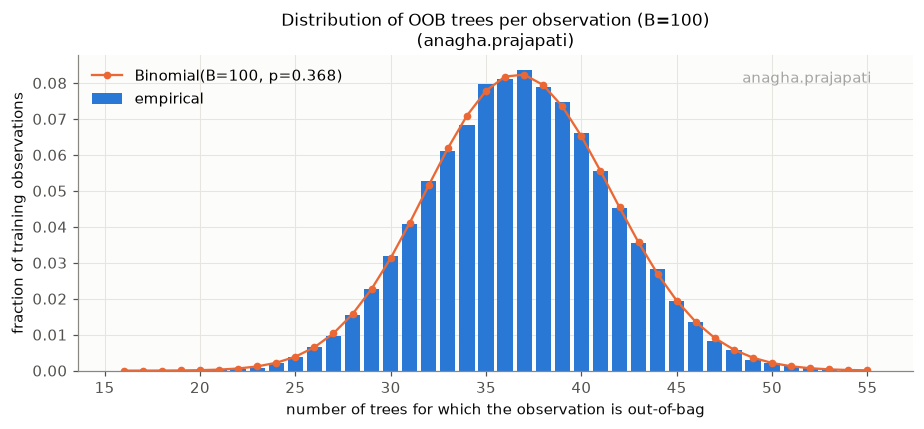

,min,5%,25%,median,75%,95%,max
OOB trees per obs.,16.0,29.0,34.0,37.0,40.0,45.0,55.0


In [33]:
rf_oob = B_forests[100]
B_oob = len(rf_oob.trees_)
cnt = rf_oob.oob_counts_
q_oob = (1 - 1 / N) ** N
print(f"Forest: B = {B_oob}, m = {rf_oob.max_features_}")
print(f"OOB trees per observation: min {cnt.min()}, max {cnt.max()}, mean {cnt.mean():.2f}, std {cnt.std():.2f}, "
      f"median {np.median(cnt):.0f}")
print(f"theory (Binomial(B, (1-1/N)^N)): mean {B_oob * q_oob:.2f}, std {math.sqrt(B_oob * q_oob * (1 - q_oob)):.2f}")
print(f"observations without any OOB tree: {rf_oob.n_without_oob_}  (coverage {rf_oob.oob_coverage_:.4%})")

ks = np.arange(cnt.min(), cnt.max() + 1)
binom = np.array([math.comb(B_oob, k) * q_oob ** k * (1 - q_oob) ** (B_oob - k) for k in ks])
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(ks, np.bincount(cnt, minlength=cnt.max() + 1)[ks] / len(cnt), color=BLUE, width=0.8, label="empirical")
ax.plot(ks, binom, "o-", color=ORANGE, markersize=4, lw=1.5, label=f"Binomial(B={B_oob}, p={q_oob:.3f})")
ax.set_xlabel("number of trees for which the observation is out-of-bag")
ax.set_ylabel("fraction of training observations")
ax.legend(loc="upper left")
titled(ax, "Distribution of OOB trees per observation (B=100)")
finish(fig, "1_5_oob_distribution")

pct = np.percentile(cnt, [0, 5, 25, 50, 75, 95, 100])
display(pd.DataFrame([pct], columns=["min", "5%", "25%", "median", "75%", "95%", "max"], index=["OOB trees per obs."]))

,OOB coverage,obs. without OOB tree,OOB accuracy,validation accuracy,OOB error,validation error,OOB - validation error
B,,,,,,,
1,0.3653,16532,0.8144,0.8090,0.1856,0.1910,-0.0055
10,0.9900,260,0.8372,0.8526,0.1628,0.1474,0.0154
50,1.0000,0,0.8542,0.8580,0.1458,0.1420,0.0038
100,1.0000,0,0.8572,0.8587,0.1428,0.1413,0.0015
250,1.0000,0,0.8591,0.8603,0.1409,0.1397,0.0011


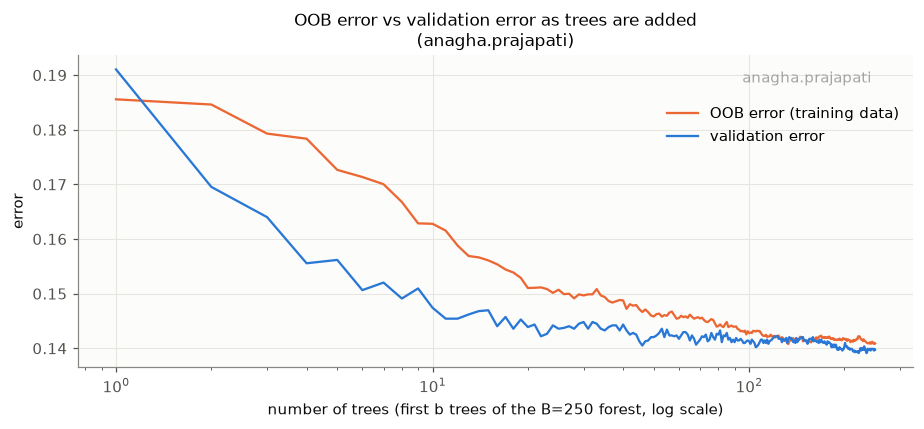

In [34]:
# OOB vs validation for every forest of the number-of-trees experiment
oob_rows = []
for B, rf in B_forests.items():
    val_acc = accuracy_score(y_val, rf.predict(X_val))
    oob_rows.append({"B": B, "OOB coverage": rf.oob_coverage_, "obs. without OOB tree": rf.n_without_oob_,
                     "OOB accuracy": rf.oob_score_, "validation accuracy": val_acc,
                     "OOB error": 1 - rf.oob_score_, "validation error": 1 - val_acc,
                     "OOB - validation error": (1 - rf.oob_score_) - (1 - val_acc)})
oob_table = pd.DataFrame(oob_rows).set_index("B")
display(fmt(oob_table).format("{:.4f}", subset=["OOB coverage", "OOB accuracy", "validation accuracy", "OOB error",
                                                 "validation error", "OOB - validation error"]))

# staged OOB error of the B=250 forest (OOB votes accumulated tree by tree)
rf250 = B_forests[250]
v = np.zeros(N, dtype=np.int64)
c = np.zeros(N, dtype=np.int64)
staged_oob_err = []
for tree, oob in zip(rf250.trees_, rf250.oob_indices_):
    v[oob] += tree.predict(X_train[oob])
    c[oob] += 1
    has = c > 0
    staged_oob_err.append(1 - accuracy_score(y_train[has], majority_vote(v[has], c[has])))
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(np.arange(1, 251), staged_oob_err, color=ORANGE, lw=1.5, label="OOB error (training data)")
ax.plot(np.arange(1, 251), staged_val_err, color=BLUE, lw=1.5, label="validation error")
ax.set_xscale("log")
ax.set_xlabel("number of trees (first b trees of the B=250 forest, log scale)")
ax.set_ylabel("error")
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.88))
titled(ax, "OOB error vs validation error as trees are added")
finish(fig, "1_5_oob_vs_validation")

**Discussion: OOB evaluation**

* **Distribution.** With $B = 100$, an observation is OOB for 36.8 trees on average (standard deviation 4.79, range 16–55). This matches the theoretical Binomial$(100, 0.368)$ distribution (mean 36.79, standard deviation 4.82) almost exactly. Every observation has at least 16 OOB trees, so the coverage is 100% and no observation needs special treatment.
* **Small $B$.** With $B = 1$ only 36.5% of the observations have an OOB prediction (16,532 have none) and it comes from a single tree. With $B = 10$, 260 observations (1.0%) still have no OOB tree. They are excluded from the OOB accuracy, as specified above.
* **OOB vs validation.** For $B = 1$ both numbers measure a single tree and agree within noise (81.4% vs 80.9%). For $B = 10$ the OOB error is clearly **higher** than the validation error (16.3% vs 14.7%). The reason is that each OOB vote uses only the ≈37% of trees that did not see the observation, so the OOB estimate behaves like a forest with about $0.37B$ trees. The staged plot shows this lag: the OOB curve sits above the validation curve and both converge to the same level. The gap shrinks to 0.38 points at $B = 50$, 0.15 at $B = 100$ and 0.11 at $B = 250$, all inside the sampling noise of the validation set (standard error ≈0.43 points).
* **Conclusion.** For a reasonably large forest the OOB error is a slightly pessimistic but close estimate of the generalisation error, and it comes **for free**, without holding out data. Here it serves as a second, independent check during model selection.

---
# 1.6 Bias–Variance and Hyperparameter Study

All forests below use $B = 100$, $m = \sqrt p = 9$, Gini and the same seed. Only the studied hyperparameter changes.

## 1.6.1 Effect of Tree Depth

,train error,val error,OOB error,generalisation gap (val - train),mean leaves/tree,mean depth,"wall-clock time (s, 12 workers)"
max_depth,,,,,,,
2,0.2408,0.2408,0.2408,-0.0000,4.0,2.0,2.8
4,0.2150,0.2141,0.2137,-0.0009,15.5,4.0,2.4
6,0.1633,0.1682,0.1654,0.0049,49.4,6.0,4.1
10,0.1321,0.1385,0.1424,0.0064,254.9,10.0,8.2
unrestricted,0.0001,0.1413,0.1428,0.1412,2791.6,45.7,26.7


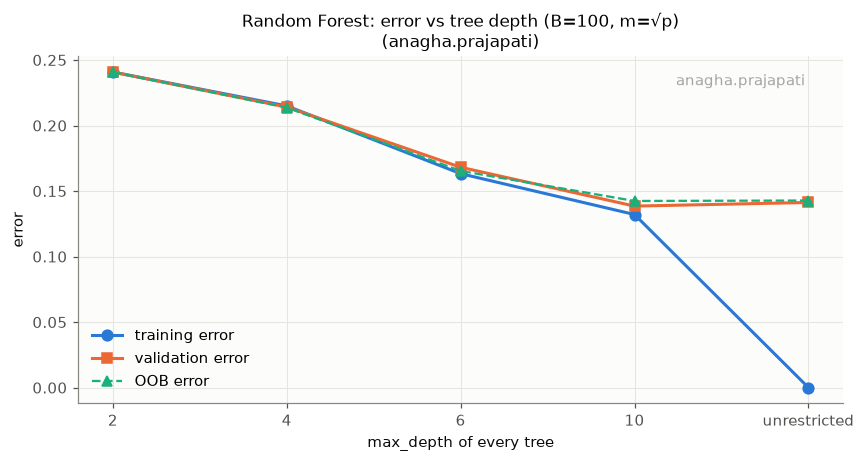

In [35]:
WALL = f"wall-clock time (s, {N_JOBS} workers)"


def rf_experiment(param_name, values, base_params):
    rows = []
    for v in values:
        params = {**base_params, param_name: v}
        rf = RandomForest(**params, random_state=SEED, n_jobs=N_JOBS).fit(X_train, y_train)
        cx = rf.complexity()
        tr, va = accuracy_score(y_train, rf.predict(X_train)), accuracy_score(y_val, rf.predict(X_val))
        rows.append({param_name: "unrestricted" if v is None else v, "train error": 1 - tr, "val error": 1 - va,
                     "OOB error": 1 - rf.oob_score_, "generalisation gap (val - train)": tr - va,
                     "mean leaves/tree": cx["mean leaves/tree"], "mean depth": cx["mean depth"],
                     WALL: rf.fit_time_})
    return pd.DataFrame(rows).set_index(param_name)


BASE = dict(n_estimators=100, max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features=M_DEFAULT)
rf_depth_table = rf_experiment("max_depth", [2, 4, 6, 10, None], BASE)
display(fmt(rf_depth_table).format("{:.4f}", subset=["train error", "val error", "OOB error", "generalisation gap (val - train)"])
        .format("{:.1f}", subset=["mean leaves/tree", "mean depth", WALL]))

fig, ax = plt.subplots(figsize=(8, 4.3))
xs = np.arange(len(rf_depth_table))
ax.plot(xs, rf_depth_table["train error"], "o-", color=BLUE, label="training error")
ax.plot(xs, rf_depth_table["val error"], "s-", color=ORANGE, label="validation error")
ax.plot(xs, rf_depth_table["OOB error"], "^--", color=AQUA, lw=1.5, label="OOB error")
ax.set_xticks(xs, [str(v) for v in rf_depth_table.index])
ax.set_xlabel("max_depth of every tree")
ax.set_ylabel("error")
ax.legend(loc="lower left")
titled(ax, "Random Forest: error vs tree depth (B=100, m=√p)")
finish(fig, "1_6_1_rf_depth")

**Discussion: depth, bias and variance**

* **Depth 2: severe underfitting (high bias).** Training, validation and OOB error are all 24.08%, exactly the majority-class error. With only two levels and 9 random candidate features per split, the trees rarely isolate a region where `>50K` is the majority, so the vote is always `<=50K`. Averaging cannot repair bias: if every tree is too simple, so is their vote.
* **Depth 4–10: bias falls.** Each extra level lets the trees model interactions (for example married × education × capital gain). The errors fall together: 21.4% at depth 4, 16.8% at depth 6 and **13.9% at depth 10** on validation. The train–validation gap stays below 1 point, so variance is still low.
* **Unrestricted depth: lowest bias, highest variance per tree.** The training error collapses to 0.01% (the trees memorise their bootstrap samples), and the generalisation gap jumps to 14.1 points. That is an overfitting signature at the level of the individual trees. The *validation* error, however, does not explode as it did for a single tree (18.5% in 1.2.3): it is 14.1%, because averaging 100 decorrelated trees cancels most of the variance.
* **Depth 10 vs unrestricted.** Depth 10 is slightly better on validation (13.9% vs 14.1%), while the OOB errors are equal (14.2% vs 14.3%). The difference is within noise, but it suggests that fully grown trees leave some residual variance that the vote does not remove, so a mild depth limit can help. This is tested in 1.6.3.
* In short: depth controls the **bias** of each tree, and the ensemble controls the **variance**. A forest can therefore afford much deeper trees than a single tree can.

## 1.6.2 Effect of Minimum Leaf Size

,train error,val error,OOB error,generalisation gap (val - train),mean leaves/tree,mean depth,"wall-clock time (s, 12 workers)"
min_samples_leaf,,,,,,,
1,0.0001,0.1413,0.1428,0.1412,2791.6,45.7,22.6
2,0.0255,0.1437,0.1419,0.1183,2527.3,44.4,24.7
5,0.0597,0.1391,0.1402,0.0794,1738.5,39.6,15.1
10,0.0918,0.1385,0.1378,0.0468,1100.0,36.2,10.6
25,0.1194,0.1364,0.1399,0.0170,505.4,28.6,8.2


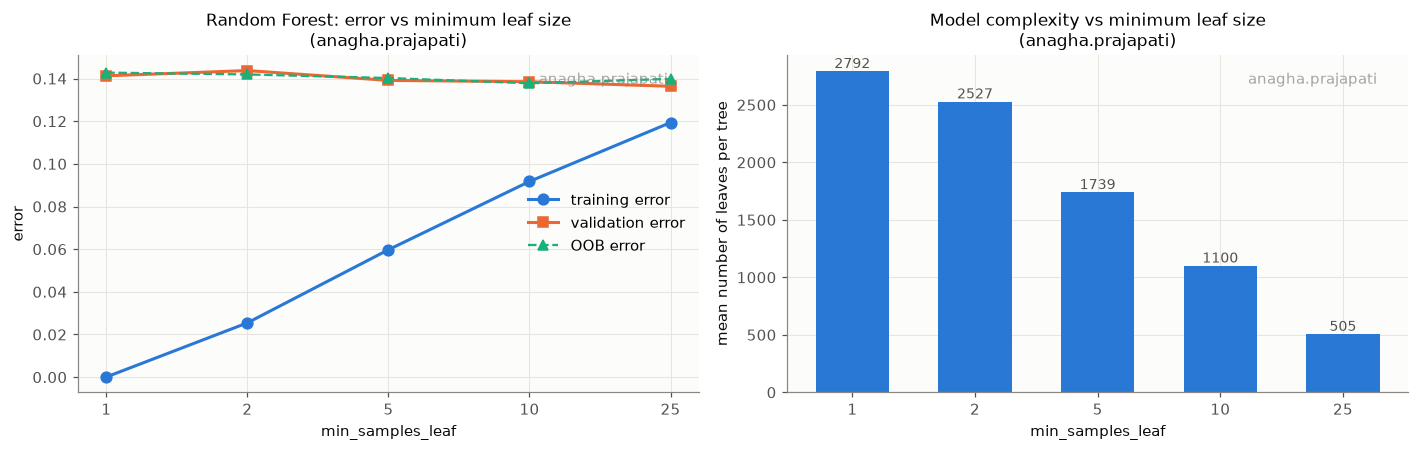

In [36]:
rf_leaf_table = rf_experiment("min_samples_leaf", [1, 2, 5, 10, 25], BASE)
display(fmt(rf_leaf_table).format("{:.4f}", subset=["train error", "val error", "OOB error", "generalisation gap (val - train)"])
        .format("{:.1f}", subset=["mean leaves/tree", "mean depth", WALL]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
xs = np.arange(len(rf_leaf_table))
ax = axes[0]
ax.plot(xs, rf_leaf_table["train error"], "o-", color=BLUE, label="training error")
ax.plot(xs, rf_leaf_table["val error"], "s-", color=ORANGE, label="validation error")
ax.plot(xs, rf_leaf_table["OOB error"], "^--", color=AQUA, lw=1.5, label="OOB error")
ax.set_xticks(xs, [str(v) for v in rf_leaf_table.index])
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("error")
ax.legend(loc="center right")
titled(ax, "Random Forest: error vs minimum leaf size")
ax = axes[1]
ax.bar(xs, rf_leaf_table["mean leaves/tree"], color=BLUE, width=0.6)
for x_, v in zip(xs, rf_leaf_table["mean leaves/tree"]):
    ax.text(x_, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(xs, [str(v) for v in rf_leaf_table.index])
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("mean number of leaves per tree")
titled(ax, "Model complexity vs minimum leaf size")
finish(fig, "1_6_2_rf_min_samples_leaf")

**Discussion: minimum leaf size**

* `min_samples_leaf` is a **smoothing / regularisation** parameter. Every leaf must contain at least that many training examples, so tiny "memorising" leaves are forbidden.
* **Complexity falls steeply.** The mean number of leaves per tree drops from 2,792 (leaf size 1) to 505 (leaf size 25), and the mean depth from 46 to 29.
* **Variance falls, bias rises.** The training error rises steadily (0.01% → 2.6% → 6.0% → 9.2% → 11.9%), because the trees can no longer fit individual points. The train–validation gap shrinks from 14.1 to 1.7 points.
* **Validation error improves slightly**, from 14.1% (leaf size 1) to 13.6% (leaf size 25), with one small non-monotone step at leaf size 2 (14.4%). The OOB error shows the same mild trend (14.3% → 14.0%, with its minimum of 13.8% at leaf size 10). Removing single-point leaves removes noise that the unrestricted trees had memorised. Within the tested range we do not yet see the validation error turn upwards; much larger leaves would eventually underfit.
* The effect is modest (about 0.5 points, close to the noise level), because averaging already provides most of the variance reduction. A larger leaf size is still attractive: for the same or better accuracy the trees are 5 times smaller and faster to train and evaluate.

## 1.6.3 Hyperparameter Selection

**Design of the manual study (validation set only, the test set is never touched).**

*Stage 1:* a grid of 27 configurations with $B = 100$ trees:
* `max_depth` ∈ {12, 20, unrestricted}: 1.6.1 showed that depth ≈10 is at least as good as unrestricted, so we test a medium limit, a loose limit and no limit;
* `max_features` m ∈ {9, 20, 44}: √p, ≈2√p and p/2, the range that performed well in 1.4.1 (m = 1 and m = p were clearly worse);
* `min_samples_leaf` ∈ {1, 5, 25}: 1.6.2 showed that larger leaves do not hurt and may help.

*Stage 2 (number of trees):* the three best stage-1 configurations are retrained with $B = 250$, to check whether more trees help.

**Selection rule:** the highest **validation accuracy**. If two configurations are within 0.1 percentage points of each other, far below the ≈0.4 pp standard error of the validation estimate, the cheaper one is preferred (fewer trees, then shallower trees). OOB accuracy is reported as an independent sanity check.

In [37]:
grid = [dict(max_depth=d, max_features=m, min_samples_leaf=l)
        for d in [12, 20, None] for m in [9, 20, 44] for l in [1, 5, 25]]
grid_rows = []
t_grid = time.perf_counter()
for cfg in grid:
    rf = RandomForest(n_estimators=100, **cfg, random_state=SEED, n_jobs=N_JOBS).fit(X_train, y_train)
    grid_rows.append({"n_estimators": 100, "max_depth": "unrestricted" if cfg["max_depth"] is None else cfg["max_depth"],
                      "max_features": cfg["max_features"], "min_samples_leaf": cfg["min_samples_leaf"],
                      "train acc": accuracy_score(y_train, rf.predict(X_train)),
                      "val acc": accuracy_score(y_val, rf.predict(X_val)), "OOB acc": rf.oob_score_,
                      WALL: rf.fit_time_, "cfg": cfg})
print(f"stage 1: {len(grid)} configurations trained in {time.perf_counter() - t_grid:.0f} s (wall-clock)")
grid_table = pd.DataFrame(grid_rows).sort_values(["val acc", "OOB acc"], ascending=False).reset_index(drop=True)
display(fmt(grid_table.drop(columns="cfg")).format("{:.4f}", subset=["train acc", "val acc", "OOB acc"])
        .format("{:.1f}", subset=[WALL]))

stage 1: 27 configurations trained in 674 s (wall-clock)


,n_estimators,max_depth,max_features,min_samples_leaf,train acc,val acc,OOB acc,"wall-clock time (s, 12 workers)"
0,100,12,44,1,0.8844,0.8667,0.8626,25.8
1,100,12,44,25,0.8718,0.8659,0.8591,21.8
2,100,20,9,1,0.9344,0.8656,0.8629,19.1
3,100,unrestricted,20,25,0.8861,0.8656,0.8616,17.6
4,100,20,20,5,0.9143,0.8653,0.8638,20.9
5,100,12,44,5,0.8797,0.8649,0.8615,22.9
6,100,20,9,25,0.8755,0.8646,0.8601,10.5
7,100,20,44,5,0.9177,0.8644,0.8631,33.1
8,100,20,20,25,0.8841,0.8643,0.8612,16.7
9,100,20,9,5,0.9030,0.8641,0.8626,14.8


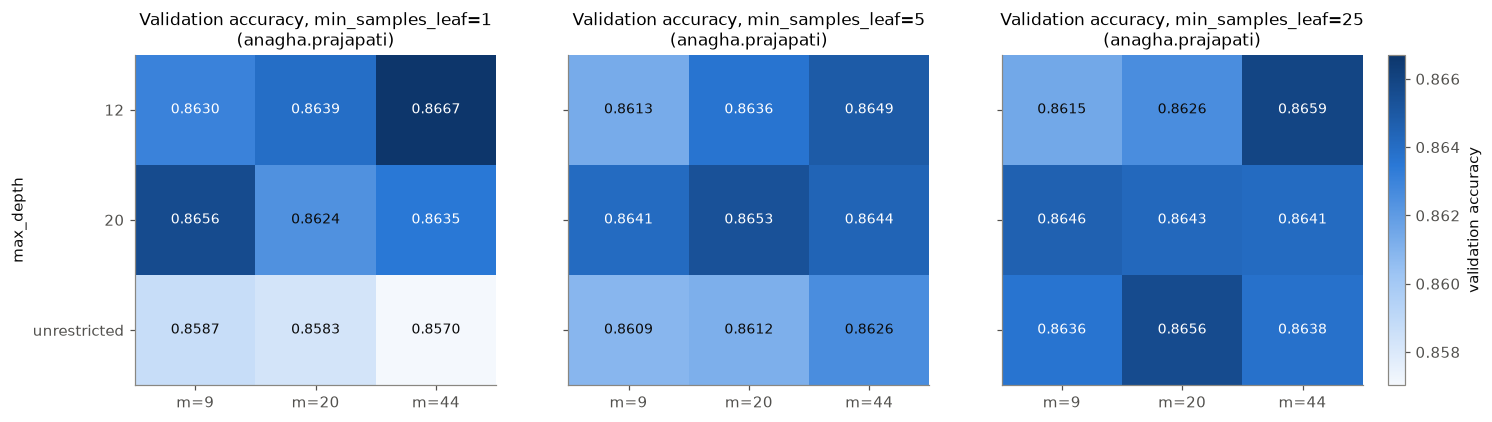

In [38]:
# heat-map view of stage 1: validation accuracy per (max_depth, max_features), one panel per min_samples_leaf
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
depth_order, m_order, leaf_order = ["12", "20", "unrestricted"], [9, 20, 44], [1, 5, 25]
gt = grid_table.assign(max_depth=grid_table["max_depth"].astype(str))
vmin, vmax = gt["val acc"].min(), gt["val acc"].max()
for ax, l in zip(axes, leaf_order):
    M = np.array([[gt.loc[(gt.max_depth == d) & (gt.max_features == m) & (gt.min_samples_leaf == l), "val acc"].item()
                   for m in m_order] for d in depth_order])
    im = ax.imshow(M, cmap=SEQUENTIAL, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.4f}", ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] > vmin + 0.6 * (vmax - vmin) else INK)
    ax.set_xticks(range(3), [f"m={m}" for m in m_order])
    ax.set_yticks(range(3), depth_order if l == 1 else [])
    ax.grid(False)
    titled(ax, f"Validation accuracy, min_samples_leaf={l}")
axes[0].set_ylabel("max_depth")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="validation accuracy")
fig.savefig(os.path.join(FIG_DIR, f"{USERNAME}_1_6_3_grid.png"), dpi=130, bbox_inches="tight")
plt.show()

In [39]:
# stage 2: the 3 best configurations with B = 250
stage2_rows = []
for _, row in grid_table.head(3).iterrows():
    rf = RandomForest(n_estimators=250, **row["cfg"], random_state=SEED, n_jobs=N_JOBS).fit(X_train, y_train)
    stage2_rows.append({**{k: row[k] for k in ["max_depth", "max_features", "min_samples_leaf"]}, "n_estimators": 250,
                        "train acc": accuracy_score(y_train, rf.predict(X_train)),
                        "val acc": accuracy_score(y_val, rf.predict(X_val)), "OOB acc": rf.oob_score_,
                        WALL: rf.fit_time_, "cfg": row["cfg"]})
    del rf
candidates_table = pd.concat([grid_table.head(3), pd.DataFrame(stage2_rows)], ignore_index=True)
display(fmt(candidates_table.drop(columns="cfg")).format("{:.4f}", subset=["train acc", "val acc", "OOB acc"])
        .format("{:.1f}", subset=[WALL]))

# selection rule: highest validation accuracy; within 0.1 pp prefer fewer trees, then shallower trees
best_val = candidates_table["val acc"].max()
near = candidates_table[candidates_table["val acc"] >= best_val - 0.001].copy()
near["depth_key"] = near["max_depth"].map(lambda d: 10**6 if d == "unrestricted" else d)
chosen = near.sort_values(["n_estimators", "depth_key", "val acc"], ascending=[True, True, False]).iloc[0]
FINAL_PARAMS = dict(n_estimators=int(chosen["n_estimators"]), **chosen["cfg"])
print("best validation accuracy among candidates:", f"{best_val:.4f}")
print("SELECTED CONFIGURATION:", FINAL_PARAMS, f"-> val acc {chosen['val acc']:.4f}, OOB acc {chosen['OOB acc']:.4f}")

,n_estimators,max_depth,max_features,min_samples_leaf,train acc,val acc,OOB acc,"wall-clock time (s, 12 workers)"
0,100,12,44,1,0.8844,0.8667,0.8626,25.8
1,100,12,44,25,0.8718,0.8659,0.8591,21.8
2,100,20,9,1,0.9344,0.8656,0.8629,19.1
3,250,12,44,1,0.8847,0.8643,0.8621,55.0
4,250,12,44,25,0.8713,0.8652,0.8594,52.2
5,250,20,9,1,0.9343,0.8653,0.8639,39.7


best validation accuracy among candidates: 0.8667
SELECTED CONFIGURATION: {'n_estimators': 100, 'max_depth': 12, 'max_features': 44, 'min_samples_leaf': 1} -> val acc 0.8667, OOB acc 0.8626


In [40]:
# refit the selected configuration once on a single core (identical trees; gives a like-for-like training time)
final_rf = RandomForest(**FINAL_PARAMS, random_state=SEED, n_jobs=1).fit(X_train, y_train)
final_val_acc = accuracy_score(y_val, final_rf.predict(X_val))
assert abs(final_val_acc - chosen["val acc"]) < 1e-12      # same forest as in the study (results do not depend on n_jobs)
print(f"final model refitted: train acc {accuracy_score(y_train, final_rf.predict(X_train)):.4f}, "
      f"val acc {final_val_acc:.4f}, OOB acc {final_rf.oob_score_:.4f}, training time {final_rf.fit_time_:.1f} s (1 core)")

final_cmp = pd.DataFrame([
    model_summary(f"best single tree (max_depth={BEST_TREE_DEPTH})", best_tree, best_tree_time),
    model_summary(f"default forest ({best_rf_name})", best_rf_so_far, best_rf_so_far.fit_time_),
    model_summary("selected (tuned) Random Forest", final_rf, final_rf.fit_time_),
]).set_index("model")
display(fmt(final_cmp).format("{:.4f}", subset=["train acc", "val acc"])
        .format("{:.2f}", subset=["train time (s, 1 core)", "mean tree depth"])
        .format("{:.1f}", subset=["work (M values examined)"]))

final model refitted: train acc 0.8844, val acc 0.8667, OOB acc 0.8626, training time 106.5 s (1 core)


,train acc,val acc,"train time (s, 1 core)",work (M values examined),trees,total leaves,total nodes,mean tree depth,max tree depth
model,,,,,,,,,
best single tree (max_depth=10),0.8712,0.8601,0.99,20.1,1,255,509,10.00,10
"default forest (RF m=9, B=250)",1.0000,0.8603,295.37,3172.1,250,700308,1400366,45.75,65
selected (tuned) Random Forest,0.8844,0.8667,106.52,1729.4,100,43076,86052,12.00,12


**Selected configuration and reasons**

> **Final model: `n_estimators = 100`, `max_depth = 12`, `max_features = 44` (p/2), `min_samples_leaf = 1`** (Gini, `min_samples_split = 2`).
> Validation accuracy **86.67%**, OOB accuracy 86.26%, training accuracy 88.44%.

* **Why this one.** It has the highest validation accuracy of all 30 candidates (27 in stage 1 plus 3 in stage 2), which is the selection rule fixed in advance. Only one other candidate is within 0.1 points (the same configuration with leaf size 25, 86.59%). It has the same number of trees and the same depth, so the tie-break rule leaves the choice unchanged.
* **More trees did not help.** Retraining the three best configurations with $B = 250$ gave 86.43%, 86.52% and 86.53%: no improvement over $B = 100$, in line with the plateau found in 1.4.3. So we keep the cheaper $B = 100$.
* **How much to trust the ranking.** The top ten configurations lie within 0.3 points of each other, less than one standard error of the validation estimate (≈0.43 points). The selected configuration itself scores 86.43% with 250 trees, so part of its 86.67% is favourable noise, and its true advantage over its neighbours is not established. Its OOB accuracy (86.26%) is among the highest in the grid (the maximum is 86.38%), which confirms it is a good configuration, not that it is uniquely the best.
* **What the study does establish** (patterns that are consistent across the heat-maps):
  * *Regularisation helps.* Fully grown trees with leaf size 1 are the worst cells (85.7–85.9%). Limiting the depth or enlarging the leaves gains 0.3–1 point.
  * *Shallower trees want more candidate features.* At depth 12, accuracy increases with m in all three panels (for example 86.30% → 86.39% → 86.67% at leaf size 1). A depth-limited tree has few splits, so each split must be good; and depth-limited trees are less correlated to begin with, so less randomisation is needed.
  * *Depth limit and leaf size are substitutes.* Unrestricted trees need leaf size 25 to reach 86.4–86.6%, while depth-12 trees gain nothing from larger leaves.
* **Compared with the earlier models** (table above): the tuned forest improves validation accuracy from 86.0% (best single tree, and default forest with 250 unrestricted trees) to 86.7%. It is also far smaller than the default forest: 43,076 leaves instead of 700,308, about a third of the measured training time and 55% of the split-search work.
* The **test set was not used** anywhere in this section.

---
# 1.7 Feature Importance and Model Interpretation

Both importances are computed for the **selected final forest**, using the p = 88 model features (one-hot columns are separate features). As an extra, we also aggregate each importance to the 13 original variables.

## 1.7.1 Impurity-Based Feature Importance (Mean Decrease in Impurity)

During growth, every split $t$ of every tree records its weighted impurity decrease
$$\Delta(t) = \frac{n_t}{N}\Big(I(t) - \frac{n_{t_L}}{n_t}I(t_L) - \frac{n_{t_R}}{n_t}I(t_R)\Big)$$
(`TreeNode.impurity_decrease`, accumulated per feature in `DecisionTree.impurity_decrease_`). The importance of feature $j$ is the sum of $\Delta(t)$ over all splits on $j$ in all trees, normalised so that $\sum_{j=1}^{p} I_j = 1$.

sum of importances = 1.000000, number of features = 88


,importance,cumulative
feature,,
marital-status=Married-civ-spouse,0.2054,0.2054
education-num,0.1836,0.3890
capital-gain,0.1778,0.5669
relationship=Husband,0.0873,0.6541
age,0.0786,0.7328
capital-loss,0.0576,0.7903
fnlwgt,0.0490,0.8393
hours-per-week,0.0484,0.8877
occupation=Exec-managerial,0.0161,0.9037


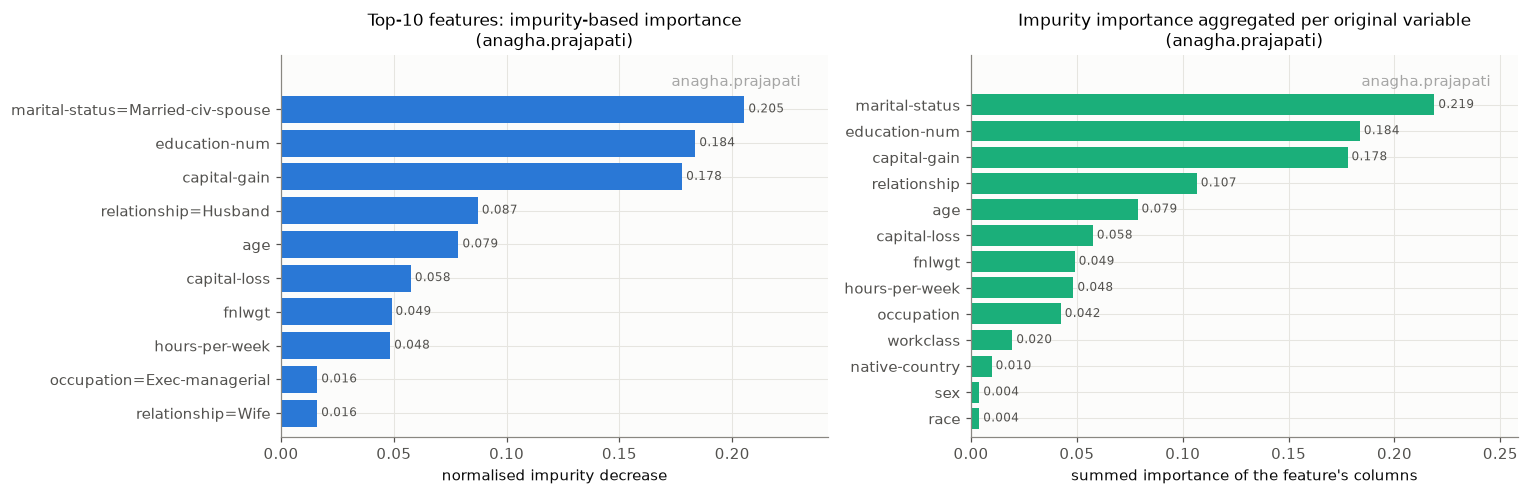

In [41]:
mdi = final_rf.feature_importances_
print(f"sum of importances = {mdi.sum():.6f}, number of features = {len(mdi)}")
mdi_series = pd.Series(mdi, index=FEATURE_NAMES).sort_values(ascending=False)
top_mdi = mdi_series.head(10).to_frame("importance")
top_mdi["cumulative"] = top_mdi["importance"].cumsum()
top_mdi.index.name = "feature"
display(fmt(top_mdi).format("{:.4f}"))

mdi_grouped = pd.Series(mdi, index=FEATURE_GROUPS).groupby(level=0).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
s = mdi_series.head(10)[::-1]
ax.barh(s.index, s.values, color=BLUE)
for i, v in enumerate(s.values):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("normalised impurity decrease")
ax.set_xlim(0, s.max() * 1.18)
ax.set_ylim(-0.7, len(s) + 0.6)
titled(ax, "Top-10 features: impurity-based importance")
ax = axes[1]
s = mdi_grouped[::-1]
ax.barh(s.index, s.values, color=AQUA)
for i, v in enumerate(s.values):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8, color=INK2)
ax.set_xlabel("summed importance of the feature's columns")
ax.set_xlim(0, s.max() * 1.18)
ax.set_ylim(-0.7, len(s) + 0.9)
titled(ax, "Impurity importance aggregated per original variable")
finish(fig, "1_7_1_impurity_importance")

## 1.7.2 Permutation Importance (validation set)

1. Compute the baseline validation accuracy of the final forest.
2. For each feature $j$, and for each of **R = 5 repeats**: randomly permute column $j$ of the validation matrix, which breaks its link with the target while keeping its marginal distribution; predict with the trained forest; record the decrease in accuracy; **restore** the column.
3. Rank the features by their **mean** decrease (± standard deviation over the repeats).

**Efficiency (exact, not an approximation):** a tree that never splits on feature $j$ gives the same prediction whatever the values of column $j$. We therefore cache every tree's prediction on the unpermuted data and re-predict only the trees that actually use $j$ (`used_features_`). The resulting vote counts are identical to re-running the whole forest.

In [42]:
def permutation_importance(forest, X, y, groups, n_repeats=5, random_state=SEED):
    """groups: list of (name, [column indices]); a group's columns are permuted together (same row permutation)."""
    rng = np.random.default_rng(random_state)
    Xw = np.array(X, dtype=np.float64, copy=True)
    tree_preds = forest.tree_predictions(Xw)                     # cached predictions on the intact data
    base_votes = tree_preds.sum(axis=0)
    B = len(forest.trees_)
    baseline = accuracy_score(y, majority_vote(base_votes, B))
    drops = np.zeros((len(groups), n_repeats))
    for g, (name, cols) in enumerate(groups):
        users = [b for b, t in enumerate(forest.trees_) if np.isin(cols, t.used_features_).any()]
        votes_unaffected = base_votes - tree_preds[users].sum(axis=0)
        original = Xw[:, cols].copy()
        for r in range(n_repeats):
            Xw[:, cols] = original[rng.permutation(len(y))]                          # 1. permute
            votes = votes_unaffected + sum(forest.trees_[b].predict(Xw) for b in users)  # 2. predict
            drops[g, r] = baseline - accuracy_score(y, majority_vote(votes, B))       # 3. decrease
            Xw[:, cols] = original                                                    # 4. restore
    return baseline, drops


t0 = time.perf_counter()
single_groups = [(name, [j]) for j, name in enumerate(FEATURE_NAMES)]
perm_baseline, perm_drops = permutation_importance(final_rf, X_val, y_val, single_groups, n_repeats=5)
print(f"baseline validation accuracy = {perm_baseline:.4f}  ({time.perf_counter() - t0:.0f} s)")
perm_table = pd.DataFrame({"mean decrease in accuracy": perm_drops.mean(1), "std": perm_drops.std(1)},
                          index=FEATURE_NAMES).sort_values("mean decrease in accuracy", ascending=False)
perm_table.index.name = "feature"
display(fmt(perm_table.head(10)).format("{:.4f}"))
print(f"features whose permutation changes nothing (never used or no effect): "
      f"{int((perm_table['mean decrease in accuracy'].abs() < 1e-12).sum())}")
print(f"features with a negative mean decrease (noise-level): {int((perm_table['mean decrease in accuracy'] < -1e-12).sum())}")

baseline validation accuracy = 0.8667  (172 s)


,mean decrease in accuracy,std
feature,,
capital-gain,0.0448,0.0013
education-num,0.0434,0.0024
marital-status=Married-civ-spouse,0.0416,0.0020
age,0.0133,0.0009
capital-loss,0.0116,0.0008
hours-per-week,0.0076,0.0011
occupation=Exec-managerial,0.0047,0.0009
fnlwgt,0.0032,0.0015
workclass=Self-emp-not-inc,0.0019,0.0006


features whose permutation changes nothing (never used or no effect): 44
features with a negative mean decrease (noise-level): 15


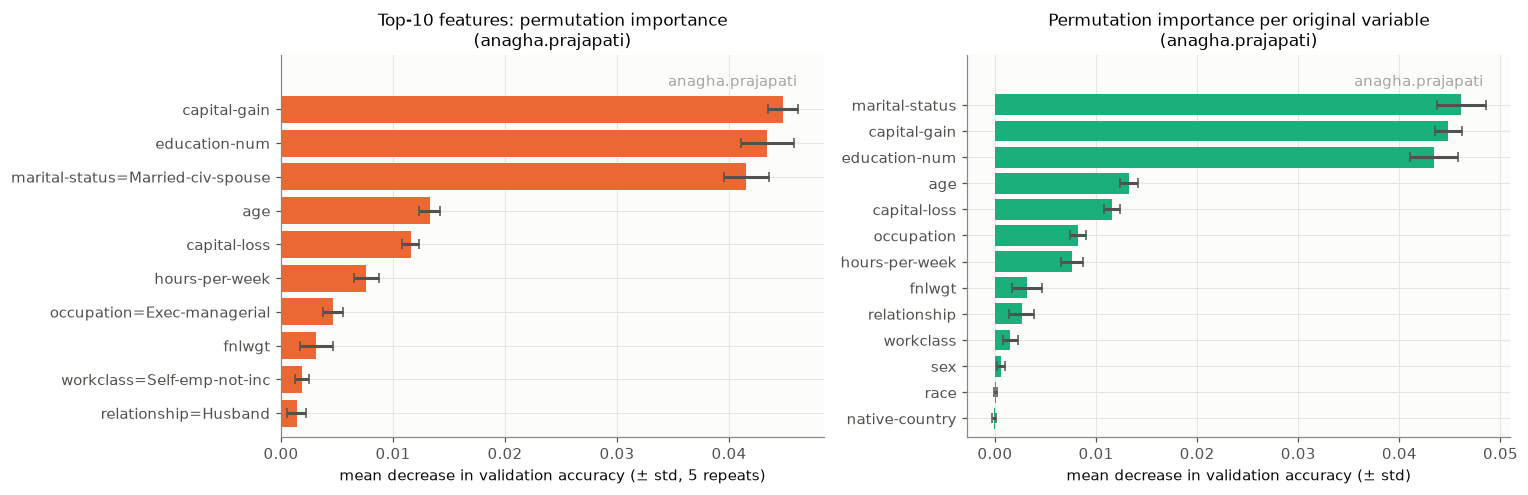

,impurity rank,permutation rank
marital-status=Married-civ-spouse,1,3
education-num,2,2
capital-gain,3,1
relationship=Husband,4,10
age,5,4
capital-loss,6,5
fnlwgt,7,8
hours-per-week,8,6
occupation=Exec-managerial,9,7
relationship=Wife,10,14


In [43]:
# extra: permute all one-hot columns of a categorical variable together (variable-level importance)
var_groups = [(v, [j for j, g in enumerate(FEATURE_GROUPS) if g == v]) for v in NUMERICAL + CAT_USED]
_, var_drops = permutation_importance(final_rf, X_val, y_val, var_groups, n_repeats=5)
var_perm = pd.DataFrame({"mean decrease in accuracy": var_drops.mean(1), "std": var_drops.std(1)},
                        index=[v for v, _ in var_groups]).sort_values("mean decrease in accuracy", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
s = perm_table.head(10)[::-1]
ax.barh(s.index, s["mean decrease in accuracy"], xerr=s["std"], color=ORANGE, ecolor=INK2, capsize=3)
ax.set_xlabel("mean decrease in validation accuracy (± std, 5 repeats)")
ax.set_ylim(-0.7, len(s) + 0.6)
titled(ax, "Top-10 features: permutation importance")
ax = axes[1]
s = var_perm[::-1]
ax.barh(s.index, s["mean decrease in accuracy"], xerr=s["std"], color=AQUA, ecolor=INK2, capsize=3)
ax.set_xlabel("mean decrease in validation accuracy (± std)")
ax.set_ylim(-0.7, len(s) + 0.9)
titled(ax, "Permutation importance per original variable")
finish(fig, "1_7_2_permutation_importance")

rank_cmp = pd.DataFrame({"impurity rank": mdi_series.rank(ascending=False).astype(int),
                         "permutation rank": perm_table["mean decrease in accuracy"].rank(ascending=False, method="min").astype(int)})
display(rank_cmp.loc[list(dict.fromkeys(list(top_mdi.index) + list(perm_table.head(10).index)))]
        .sort_values("impurity rank"))

**Discussion: what drives the predictions**

* **Both methods agree on the top three**, in slightly different order: being married (`marital-status=Married-civ-spouse`), years of education (`education-num`) and `capital-gain`. Together they carry 57% of the total impurity decrease, and permuting any one of them costs 4.2–4.5 points of validation accuracy; no other feature costs more than 1.3 points. Next come `age`, `capital-loss` and `hours-per-week`.
* **The forest uses few features.** The top 8 features hold 89% of the impurity importance. Permuting any of 44 of the 88 columns changes nothing at all, and 15 more have a tiny negative mean decrease, which is pure noise. `race`, `sex` and `native-country` are nearly irrelevant once the other variables are known (variable-level permutation decreases of about 0.0005 or less).
* **Where the two methods disagree, and why.**
  * `relationship=Husband` is 4th by impurity (0.087) but only 10th by permutation (0.0014). It carries almost the same information as `Married-civ-spouse` (plus `sex`). The trees often split on it, which earns impurity credit, but when it alone is permuted the forest recovers the information from its correlated partner, so accuracy hardly drops. Permutation importance **understates correlated features**; impurity importance **splits the credit** between them. At variable level the same happens: `relationship` has 10.7% of the impurity importance but a permutation decrease of only about 0.003.
  * `fnlwgt` has 4.9% of the impurity importance (7th) although its correlation with the target is −0.009 and permuting it costs only 0.3 points. Impurity importance is computed on the **training** data and is **biased towards continuous features with many distinct values** (`fnlwgt` has over 28,000): such a feature offers so many thresholds that some split reduces training impurity by chance, especially deep in the trees. Permutation importance is measured on held-out data and is not fooled in this way.
* **Which to trust.** Permutation importance on validation data answers the more relevant question (how much does the model's *generalisation* depend on this feature?), but it must be read together with the correlation structure. Impurity importance is free and a useful first look. Aggregating the one-hot columns per original variable (right-hand plots) gives the fairest picture for categorical variables: `marital-status`, `capital-gain` and `education-num` are level at the top by permutation (about 0.043–0.046 each), followed by `age`, `capital-loss`, `occupation` and `hours-per-week`.

---
# 1.8 Final Evaluation and Error Analysis

Model selection is complete: the configuration, the trees and the split were all fixed using only train and validation data. **Only now** is the official test set used, exactly once, for the selected forest. `>50K` is the **positive class**. All metrics are implemented from scratch:

* confusion matrix $\begin{pmatrix} TN & FP \\ FN & TP \end{pmatrix}$ (rows: actual, columns: predicted);
* accuracy $=\frac{TP+TN}{N}$, precision $=\frac{TP}{TP+FP}$, recall $=\frac{TP}{TP+FN}$, $F_1 = \frac{2PR}{P+R}$.

If a denominator is 0 (for example, the precision of a model that never predicts `>50K`), the metric is reported as 0 and flagged as undefined.

In [44]:
def confusion_matrix_binary(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])


def safe_div(a, b):
    return (a / b, True) if b > 0 else (0.0, False)


def classification_metrics(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix_binary(y_true, y_pred)
    acc = (tp + tn) / (tp + tn + fp + fn)
    precision, p_def = safe_div(tp, tp + fp)
    recall, r_def = safe_div(tp, tp + fn)
    f1, f_def = safe_div(2 * precision * recall, precision + recall)
    note = "" if (p_def and r_def and f_def) else "precision/F1 undefined (no positive predictions) -> reported as 0"
    return {"accuracy": acc, "precision": precision, "recall": recall, "F1": f1,
            "TN": tn, "FP": fp, "FN": fn, "TP": tp, "note": note}


# --- final model on the test set (evaluated once)
test_pred_rf = final_rf.predict(X_test)
# --- majority-class baseline: always predict the most frequent TRAINING class
majority_class = int(np.bincount(y_train).argmax())
test_pred_base = np.full(len(y_test), majority_class)
# --- reference: the best single tree (also fixed before looking at the test set)
test_pred_tree = best_tree.predict(X_test)

test_results = pd.DataFrame({
    f"Random Forest (selected: {FINAL_PARAMS})": classification_metrics(y_test, test_pred_rf),
    f"best single tree (max_depth={BEST_TREE_DEPTH})": classification_metrics(y_test, test_pred_tree),
    f"majority-class baseline (always '{'>50K' if majority_class else '<=50K'}')": classification_metrics(y_test, test_pred_base),
}).T
METRIC_COLS = ["accuracy", "precision", "recall", "F1"]
test_results[METRIC_COLS] = test_results[METRIC_COLS].astype(float)
test_results[["TN", "FP", "FN", "TP"]] = test_results[["TN", "FP", "FN", "TP"]].astype(int)
display(fmt(test_results).format("{:.4f}", subset=METRIC_COLS))
print(f"Test set: {len(y_test)} individuals, {int(y_test.sum())} positive (>50K) = {y_test.mean():.2%}")
print(f"Validation accuracy of the final forest: {final_val_acc:.4f} | test accuracy: {test_results.iloc[0]['accuracy']:.4f}")

,accuracy,precision,recall,F1,TN,FP,FN,TP,note
"Random Forest (selected: {'n_estimators': 100, 'max_depth': 12, 'max_features': 44, 'min_samples_leaf': 1})",0.8646,0.7754,0.6006,0.6769,11766,669,1536,2310,
best single tree (max_depth=10),0.8581,0.7493,0.5998,0.6663,11663,772,1539,2307,
majority-class baseline (always '<=50K'),0.7638,0.0000,0.0000,0.0000,12435,0,3846,0,precision/F1 undefined (no positive predictions) -> reported as 0


Test set: 16281 individuals, 3846 positive (>50K) = 23.62%
Validation accuracy of the final forest: 0.8667 | test accuracy: 0.8646


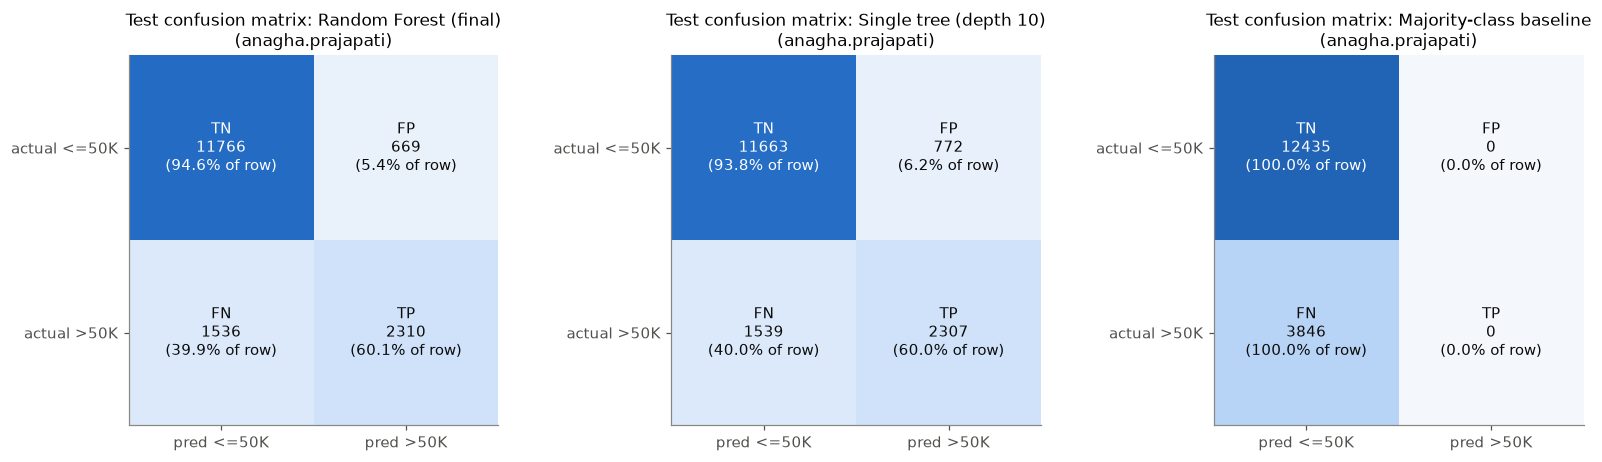

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, pred) in zip(axes, [("Random Forest (final)", test_pred_rf),
                                   (f"Single tree (depth {BEST_TREE_DEPTH})", test_pred_tree),
                                   ("Majority-class baseline", test_pred_base)]):
    cm = confusion_matrix_binary(y_test, pred)
    ax.imshow(cm, cmap=SEQUENTIAL, vmin=0, vmax=len(y_test))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{['TN', 'FP', 'FN', 'TP'][2 * i + j]}\n{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%} of row)",
                    ha="center", va="center", fontsize=10, color="white" if cm[i, j] > 0.45 * len(y_test) else INK)
    ax.set_xticks([0, 1], ["pred <=50K", "pred >50K"])
    ax.set_yticks([0, 1], ["actual <=50K", "actual >50K"])
    ax.grid(False)
    titled(ax, f"Test confusion matrix: {name}")
finish(fig, "1_8_confusion_matrices")

### Error analysis

Where does the final forest make its mistakes? We look at (a) how confident the vote is for correct versus wrong predictions, and (b) the error rates of subgroups of the test population.

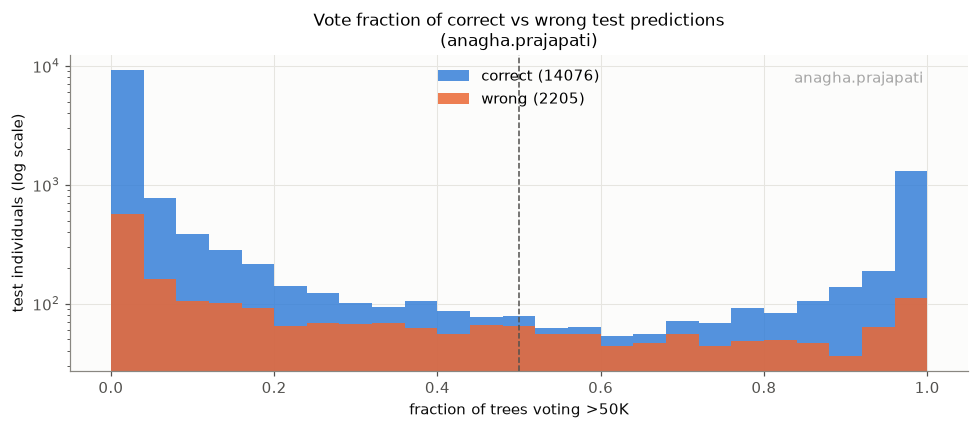

share of errors with vote fraction in [0.3, 0.7]: 25.7% (vs 5.3% of correct predictions)
error rate when the vote is decisive (<0.1 or >0.9): 7.58%; when it is close (0.3-0.7): 43.27%


In [46]:
vote_frac = final_rf.predict_votes(X_test) / len(final_rf.trees_)
correct = test_pred_rf == y_test
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 26)
ax.hist(vote_frac[correct], bins=bins, color=BLUE, alpha=0.8, label=f"correct ({correct.sum()})")
ax.hist(vote_frac[~correct], bins=bins, color=ORANGE, alpha=0.85, label=f"wrong ({(~correct).sum()})")
ax.axvline(0.5, color=INK2, ls="--", lw=1)
ax.set_yscale("log")
ax.set_xlabel("fraction of trees voting >50K")
ax.set_ylabel("test individuals (log scale)")
ax.legend(loc="upper center")
titled(ax, "Vote fraction of correct vs wrong test predictions")
finish(fig, "1_8_vote_fraction")
near_half = np.abs(vote_frac - 0.5) < 0.2
print(f"share of errors with vote fraction in [0.3, 0.7]: {near_half[~correct].mean():.1%} "
      f"(vs {near_half[correct].mean():.1%} of correct predictions)")
print(f"error rate when the vote is decisive (<0.1 or >0.9): {1 - correct[(vote_frac < 0.1) | (vote_frac > 0.9)].mean():.2%}; "
      f"when it is close (0.3-0.7): {1 - correct[near_half].mean():.2%}")

In [47]:
analysis = test_imp.assign(y=y_test, pred=test_pred_rf, err=(test_pred_rf != y_test).astype(int),
                           fn=((y_test == 1) & (test_pred_rf == 0)).astype(int),
                           fp=((y_test == 0) & (test_pred_rf == 1)).astype(int))
analysis["age band"] = pd.cut(analysis["age"], [16, 25, 35, 45, 55, 65, 100], right=False)
analysis["education level"] = pd.cut(analysis["education-num"], [0, 9, 10, 13, 17], right=False,
                                     labels=["< HS-grad", "HS-grad", "Some college/Assoc", "Bachelors+"])
analysis["married (civ-spouse)"] = np.where(analysis["marital-status"] == "Married-civ-spouse", "yes", "no")


def group_errors(col):
    g = analysis.groupby(col, observed=True)
    out = pd.DataFrame({"n": g.size(), "actual >50K rate": g["y"].mean(), "predicted >50K rate": g["pred"].mean(),
                        "error rate": g["err"].mean(), "FP": g["fp"].sum(), "FN": g["fn"].sum()})
    out.index = [f"{col} = {v}" for v in out.index]
    return out


err_table = pd.concat([group_errors(c) for c in ["married (civ-spouse)", "sex", "education level", "age band"]])
display(fmt(err_table).format({"actual >50K rate": "{:.3f}", "predicted >50K rate": "{:.3f}", "error rate": "{:.3f}"}))
print(f"overall test error rate: {1 - correct.mean():.4f}; FP = {int(analysis.fp.sum())}, FN = {int(analysis.fn.sum())}")

,n,actual >50K rate,predicted >50K rate,error rate,FP,FN
married (civ-spouse) = no,8878,0.062,0.027,0.044,38,356
married (civ-spouse) = yes,7403,0.445,0.371,0.245,631,1180
sex = Female,5421,0.109,0.073,0.065,79,273
sex = Male,10860,0.300,0.238,0.171,590,1263
education level = < HS-grad,2155,0.057,0.012,0.048,4,100
education level = HS-grad,5283,0.157,0.038,0.123,13,639
education level = Some college/Assoc,4800,0.205,0.122,0.144,147,544
education level = Bachelors+,4043,0.473,0.535,0.187,505,253
"age band = [16, 25)",2862,0.011,0.003,0.009,2,24
"age band = [25, 35)",4098,0.168,0.118,0.118,138,344


overall test error rate: 0.1354; FP = 669, FN = 1536


**Discussion: final results and error analysis**

**Final test performance (official `adult.test`, 16,281 individuals, evaluated once).**

| model | accuracy | precision | recall | F1 |
|---|---|---|---|---|
| **Random Forest (selected)** | **0.8646** | **0.7754** | **0.6006** | **0.6769** |
| best single tree (depth 10) | 0.8581 | 0.7493 | 0.5998 | 0.6663 |
| majority-class baseline | 0.7638 | 0 (undefined) | 0 | 0 (undefined) |

Confusion matrix of the forest: TN = 11,766, FP = 669, FN = 1,536, TP = 2,310.

* **Against the baseline.** Always predicting `<=50K` is right 76.38% of the time but finds no high earner at all (recall 0; precision and F1 are undefined and reported as 0). The forest is 10.1 points more accurate, which removes 43% of the baseline's errors (error 23.62% → 13.54%), and it has a real F1 of 0.68.
* **Against the single tree.** The forest is 0.65 points more accurate. Recall is the same (60.1% vs 60.0%); the gain comes from **precision** (77.5% vs 74.9%): 103 fewer false positives. The standard error of one test accuracy is about 0.27 points, so this difference is modest but clearer than on the validation set.
* **Generalisation.** Test accuracy (86.46%) is only 0.2 points below validation accuracy (86.67%). The small drop is the expected price of having selected the best of 30 configurations on the validation set; there is no sign of overfitting to it.

**Error analysis.**
* **Most errors are false negatives.** Of the 2,205 errors, 1,536 (70%) are high earners predicted as `<=50K`, and only 669 are false positives. The model is conservative: it predicts `>50K` for 18.3% of people although 23.6% are. With a 76/24 class imbalance and a plain majority vote (threshold 0.5), a leaf needs a clear `>50K` majority before it predicts positive, so ambiguous cases default to the majority class. The result is good precision (0.78) and mediocre recall (0.60).
* **Errors sit near the decision boundary.** When the vote is decisive (below 10% or above 90% of the trees) the error rate is 7.6%; when it is close (30–70%) it is 43%, almost a coin flip. So the vote fraction is a useful confidence score. Even so, three quarters of the errors have a vote outside 30–70%: for many people the recorded features simply do not determine income.
* **Errors concentrate where the classes are balanced.**
  * *Married people* (45% earn >50K) have a 24.5% error rate against 4.4% for everyone else, and account for 82% of all errors (1,811 of 2,205).
  * *Men* (30% positive) have a 17.1% error rate, *women* (11% positive) 6.5%. This mostly reflects the base rates: a group that is nearly all negative is easy to predict.
  * *Age 35–54* is the hardest band (19% errors); people under 25 are almost always `<=50K` (0.9% errors).
* **Opposite biases by education.** For `HS-grad` the model predicts `>50K` for only 3.8% of people although 15.7% are, giving 639 false negatives against 13 false positives. For `Bachelors+` it over-predicts (53.5% predicted vs 47.3% actual), with 505 false positives against 253 false negatives. The forest leans heavily on education, which is right on average and wrong for the well-paid high-school graduate and the modestly paid graduate.
* **What would help.** (1) Choosing the vote threshold on the validation set instead of fixing it at 0.5, or weighting the classes, would trade precision for recall if finding high earners matters more. (2) The remaining errors are mostly not a modelling problem: variables such as job seniority, employer, or region are not in the data, and published results for this data set are mostly in the 13–15% error range.

---
# Summary of results

In [48]:
summary = pd.DataFrame([
    {"experiment": "1.1 preprocessing", "result": f"p = {p} features (education removed as redundant); "
     f"train/val/test = {len(y_train)}/{len(y_val)}/{len(y_test)}"},
    {"experiment": "1.2 best single tree", "result": f"max_depth={BEST_TREE_DEPTH}: val acc {accuracy_score(y_val, best_tree.predict(X_val)):.4f}"},
    {"experiment": "1.2 unrestricted tree", "result": f"train acc {depth_table.loc['unrestricted', 'train acc']:.4f}, "
     f"val acc {depth_table.loc['unrestricted', 'val acc']:.4f} (overfits)"},
    {"experiment": "1.3 bootstrap", "result": f"mean unique fraction {boot_table['fraction unique'].mean():.4f} vs 1-1/e = {theory_limit:.4f}"},
    {"experiment": "1.3 bagging (B=100)", "result": f"val acc {bag_table.loc[100, 'val acc']:.4f}"},
    {"experiment": "1.4 RF, m sweep (B=100)", "result": ", ".join(f"m={m}: {a:.4f}" for m, a in m_table['val acc'].items())},
    {"experiment": "1.4 RF, B sweep (m=√p)", "result": ", ".join(f"B={b}: {a:.4f}" for b, a in B_table['val acc'].items())},
    {"experiment": "1.5 OOB (B=100)", "result": f"OOB acc {B_forests[100].oob_score_:.4f} vs val acc {B_table.loc[100, 'val acc']:.4f}"},
    {"experiment": "1.6 selected model", "result": f"{FINAL_PARAMS}: val acc {final_val_acc:.4f}"},
    {"experiment": "1.7 top features", "result": f"impurity: {', '.join(mdi_series.index[:3])} | permutation: {', '.join(perm_table.index[:3])}"},
    {"experiment": "1.8 test set (final RF)", "result": ", ".join(f"{k} {test_results.iloc[0][k]:.4f}" for k in ['accuracy', 'precision', 'recall', 'F1'])},
    {"experiment": "1.8 test set (majority baseline)", "result": ", ".join(f"{k} {test_results.iloc[2][k]:.4f}" for k in ['accuracy', 'precision', 'recall', 'F1'])},
]).set_index("experiment")
with pd.option_context("display.max_colwidth", 200):
    display(summary)

,result
experiment,
1.1 preprocessing,p = 88 features (education removed as redundant); train/val/test = 26049/6512/16281
1.2 best single tree,max_depth=10: val acc 0.8601
1.2 unrestricted tree,"train acc 1.0000, val acc 0.8153 (overfits)"
1.3 bootstrap,mean unique fraction 0.6326 vs 1-1/e = 0.6321
1.3 bagging (B=100),val acc 0.8515
"1.4 RF, m sweep (B=100)","m=1: 0.8506, m=9: 0.8587, m=44: 0.8570, m=88: 0.8515"
"1.4 RF, B sweep (m=√p)","B=1: 0.8090, B=10: 0.8526, B=50: 0.8580, B=100: 0.8587, B=250: 0.8603"
1.5 OOB (B=100),OOB acc 0.8572 vs val acc 0.8587
1.6 selected model,"{'n_estimators': 100, 'max_depth': 12, 'max_features': 44, 'min_samples_leaf': 1}: val acc 0.8667"


---
### AI tool usage declaration

*(Required by the assignment if AI tools were used. Add a shareable link to, or a screenshot of, the AI conversation here, and briefly describe how you verified and modified the generated content. For example: the split search is verified against a literal loop implementation in 1.2.1, `predict` against a node-by-node walk in 1.2.2, the bootstrap fractions against theory in 1.3.1, and bagging against `RandomForest(max_features=p)` in 1.4.2.)*